In [80]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

# Filter out warnings
import warnings
warnings.filterwarnings("ignore")

# Data importing and Exploration

In [81]:
# Import the data
df = pd.read_csv('Final_Dataset.csv', index_col=0)
df = df.sample(frac=1).reset_index(drop=True)
df

,Player,Position,Team,Comp,Age,MP,Min,Goals,Ast,G+A,...,Shots Blocked,Interceptions,Clearances,Errors,Dribbles Successful,Dribble Distance,Mistakes,Ball Recoveries,Air Duels Won%,Values
0,Dominik Javorcek,DF,holstein kiel,de Bundesliga,22-089,8,194,0,2,2,...,1,3,14,1,1,581,2,4,50.0,550000.0
1,Jesus Santiago,MF,getafe,es La Liga,20-250,14,316,0,0,0,...,1,0,3,0,0,329,7,18,20.0,1000000.0
2,Javier Manquillo,DF,celta vigo,es La Liga,30-270,10,515,0,0,0,...,0,7,14,0,0,1582,1,18,38.5,1800000.0
3,Ignatius Ganago,"FW,MF",nantes,fr Ligue 1,25-349,11,241,0,0,0,...,7,4,2,0,5,169,8,7,36.4,1800000.0
4,Jean-Philippe Gbamin,MF,nantes,fr Ligue 1,29-127,13,213,0,0,0,...,2,3,2,0,1,427,5,13,70.0,2000000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1984,Lucas Beraldo,DF,paris s-g,fr Ligue 1,21-067,13,1085,1,0,1,...,5,13,25,1,0,6490,5,55,63.0,30000000.0
1985,Pathe Ciss,MF,rayo vallecano,es La Liga,30-320,17,872,1,1,2,...,11,13,29,1,7,2035,9,54,61.8,2000000.0
1986,Khalil Fayad,"MF,FW",montpellier,fr Ligue 1,20-235,8,346,0,0,0,...,4,4,6,1,1,781,2,21,50.0,4000000.0
1987,Carlens Arcus,DF,angers,fr Ligue 1,28-216,19,1454,0,1,1,...,3,23,57,2,6,3406,9,58,61.5,1500000.0


In [82]:
df.columns

Index(['Player', 'Position', 'Team', 'Comp', 'Age', 'MP', 'Min', 'Goals',
       'Ast', 'G+A', 'xG', 'xA', 'SoT%', 'npxG/Sh', 'G-xG', 'Pass Cmp%',
       'Through Balls', 'Switch Passes', 'Crosses', 'Shot Creating Actions',
       'Def Action to Shot', 'Tackles', 'Shots Blocked', 'Interceptions',
       'Clearances', 'Errors', 'Dribbles Successful', 'Dribble Distance',
       'Mistakes', 'Ball Recoveries', 'Air Duels Won%', 'Values'],
      dtype='str')

In [83]:
df.info();

<class 'pandas.DataFrame'>
RangeIndex: 1989 entries, 0 to 1988
Data columns (total 32 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Player                 1989 non-null   str    
 1   Position               1989 non-null   str    
 2   Team                   1989 non-null   str    
 3   Comp                   1989 non-null   str    
 4   Age                    1989 non-null   str    
 5   MP                     1989 non-null   int64  
 6   Min                    1989 non-null   int64  
 7   Goals                  1989 non-null   int64  
 8   Ast                    1989 non-null   int64  
 9   G+A                    1989 non-null   int64  
 10  xG                     1989 non-null   float64
 11  xA                     1989 non-null   float64
 12  SoT%                   1989 non-null   float64
 13  npxG/Sh                1989 non-null   float64
 14  G-xG                   1989 non-null   float64
 15  Pass Cmp%      

In [84]:
# Look at the values of the column Comp
df['Comp'].value_counts()

Comp
es La Liga            436
it Serie A            428
eng Premier League    403
fr Ligue 1            362
de Bundesliga         360
Name: count, dtype: int64

In [85]:
# Rename the league names with proper names
df['Comp'] = df['Comp'].replace({"eng Premier League": "Premier League"})
df['Comp'] = df['Comp'].replace({"it Serie A": "Serie A"})
df['Comp'] = df['Comp'].replace({"es La Liga": "La Liga"})
df['Comp'] = df['Comp'].replace({"fr Ligue 1": "Ligue 1"})
df['Comp'] = df['Comp'].replace({"de Bundesliga": "Bundesliga"})

# Check the values again
df['Comp'].value_counts()

Comp
La Liga           436
Serie A           428
Premier League    403
Ligue 1           362
Bundesliga        360
Name: count, dtype: int64

### Small additional data cleaning

In [86]:
# since age is in years - days format so removed the days from there
df['Age'] = df['Age'].astype(str).str.split('-').str[0].astype(int)
df['Position'] = df['Position'].str.split(',').str[0]

In [92]:
df['Value Team'] = (
    df.groupby('Team')['Values'].transform('sum')
    - df['Values']
)

df['Team Value Group'] = pd.cut(
    df['Value Team'],
    bins=[-np.inf, 100_000_000, 300_000_000,
          600_000_000, np.inf],
    labels=[1, 2, 3, 4],
    right=False
)

df

,Player,Position,Team,Comp,Age,MP,Min,Goals,Ast,G+A,...,Clearances,Errors,Dribbles Successful,Dribble Distance,Mistakes,Ball Recoveries,Air Duels Won%,Values,Value Team,Team Value Group
0,Dominik Javorcek,DF,holstein kiel,Bundesliga,22,8,194,0,2,2,...,14,1,1,581,2,4,50.0,550000.0,44300000.0,1
1,Jesus Santiago,MF,getafe,La Liga,20,14,316,0,0,0,...,3,0,0,329,7,18,20.0,1000000.0,78200000.0,1
2,Javier Manquillo,DF,celta vigo,La Liga,30,10,515,0,0,0,...,14,0,0,1582,1,18,38.5,1800000.0,121800000.0,2
3,Ignatius Ganago,FW,nantes,Ligue 1,25,11,241,0,0,0,...,2,0,5,169,8,7,36.4,1800000.0,83000000.0,1
4,Jean-Philippe Gbamin,MF,nantes,Ligue 1,29,13,213,0,0,0,...,2,0,1,427,5,13,70.0,2000000.0,82800000.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1984,Lucas Beraldo,DF,paris s-g,Ligue 1,21,13,1085,1,0,1,...,25,1,0,6490,5,55,63.0,30000000.0,702500000.0,4
1985,Pathe Ciss,MF,rayo vallecano,La Liga,30,17,872,1,1,2,...,29,1,7,2035,9,54,61.8,2000000.0,85900000.0,1
1986,Khalil Fayad,MF,montpellier,Ligue 1,20,8,346,0,0,0,...,6,1,1,781,2,21,50.0,4000000.0,113400000.0,2
1987,Carlens Arcus,DF,angers,Ligue 1,28,19,1454,0,1,1,...,57,2,6,3406,9,58,61.5,1500000.0,42250000.0,1


# Data visualization

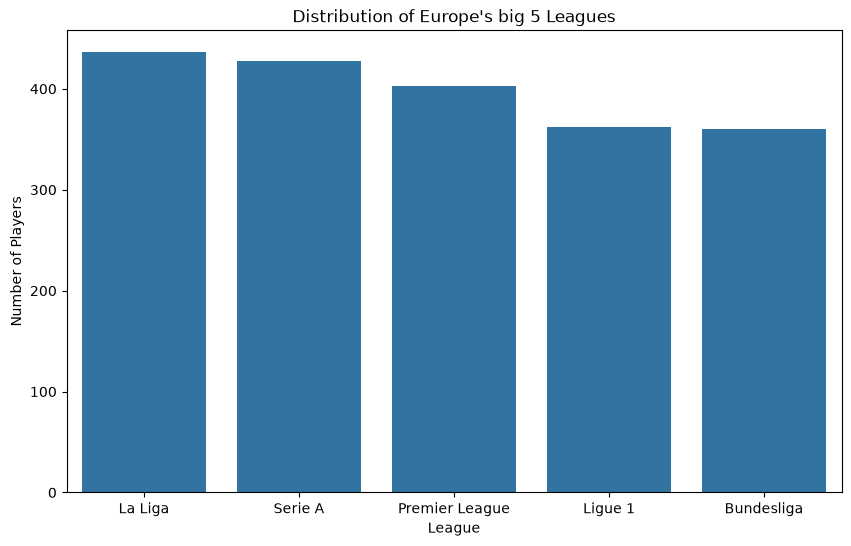

In [5]:
# Visualizing the distribution of leagues
plt.figure(figsize=(10,6))
sns.barplot(x=df['Comp'].value_counts().index, y=df['Comp'].value_counts().values)
plt.xlabel('League')
plt.ylabel('Number of Players')
plt.title("Distribution of Europe's big 5 Leagues")
plt.show()

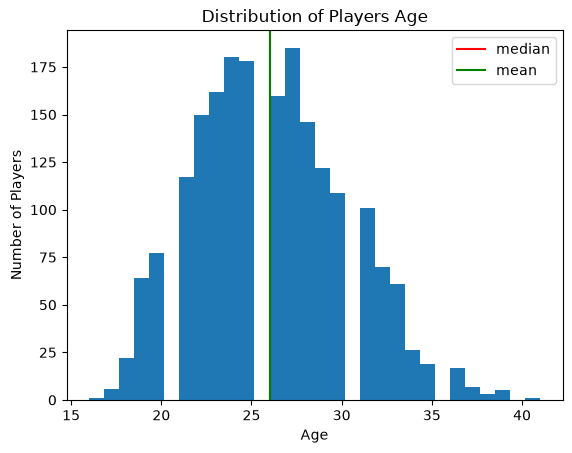

In [6]:
# Plot a histogram to show the distribution of the players' age
plt.figure()
plt.hist(df['Age'], bins=30)
# add vertical line to show the median and mean age
plt.axvline(df['Age'].median(), color='r', label='median')
plt.axvline(df['Age'].mean(), color='g', label='mean')
plt.xlabel('Age')
plt.ylabel('Number of Players')
plt.title('Distribution of Players Age')
plt.legend()
plt.show()

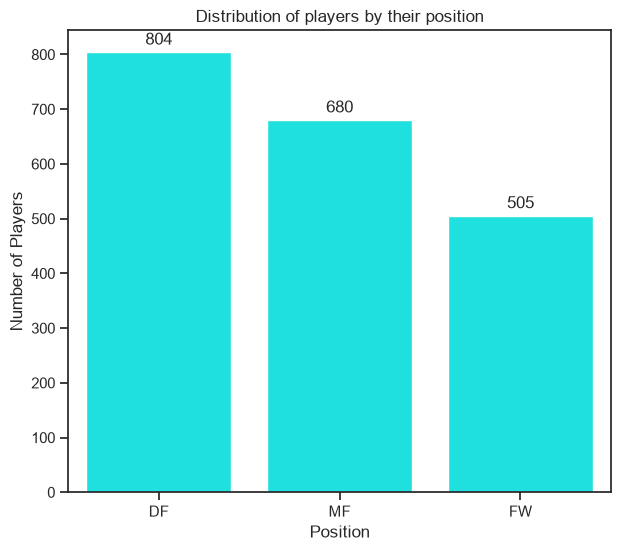

In [68]:
# players by their positions
plt.figure(figsize=(7,6))
sns.barplot(x=df['Position'].value_counts().index, y=df['Position'].value_counts().values, color="cyan")
plt.xlabel('Position')
plt.ylabel('Number of Players')
plt.title("Distribution of players by their position")

for container in plt.gca().containers:
    plt.gca().bar_label(container, padding=3)
plt.show()

In [7]:
df['Values'].describe()

count    1.989000e+03
mean     1.419932e+07
std      1.912377e+07
min      1.500000e+05
25%      3.000000e+06
50%      8.000000e+06
75%      1.700000e+07
max      2.000000e+08
Name: Values, dtype: float64

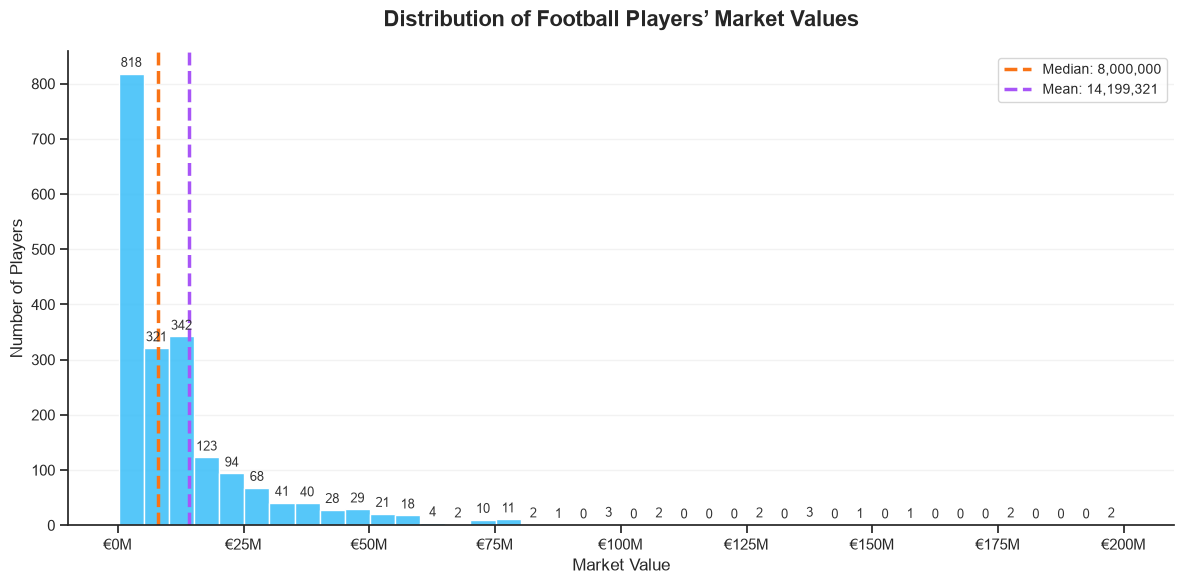

In [8]:
# imp : distribution of players market value
from matplotlib.ticker import FuncFormatter

# sns - seaborn 
sns.set_theme(style="ticks", context="notebook")

fig, ax = plt.subplots(figsize=(12, 6))

sns.histplot(
    data=df,
    x='Values',
    bins=40,
    color='#38BDF8',
    edgecolor='white',
    alpha=0.85,
    ax=ax
)

median = df['Values'].median()
mean = df['Values'].mean()

ax.axvline(
    median, color='#F97316', linestyle='--',
    linewidth=2.5, label=f'Median: {median:,.0f}'
)

ax.axvline(
    mean, color='#A855F7', linestyle='--',
    linewidth=2.5, label=f'Mean: {mean:,.0f}'
)

ax.set_title(
    'Distribution of Football Players’ Market Values',
    fontsize=16, fontweight='bold', pad=18
)
ax.set_xlabel('Market Value', fontsize=12)
ax.set_ylabel('Number of Players', fontsize=12)

ax.bar_label(
    ax.containers[0], 
    fmt='%g',          
    padding=3,         
    fontsize=9,        
    color='#333'
)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'€{x/1e6:.0f}M')
)

ax.legend(frameon=True, fontsize=10)
ax.grid(axis='y', alpha=0.25)
ax.grid(axis='x', visible=False)
sns.despine()
plt.tight_layout()
plt.show()

In [39]:
# The number of players in the dataframe
# print("Number of unique players: ", df['Player'].nunique)
df['Player'].nunique()

1988

Top 10 players with the highest market value

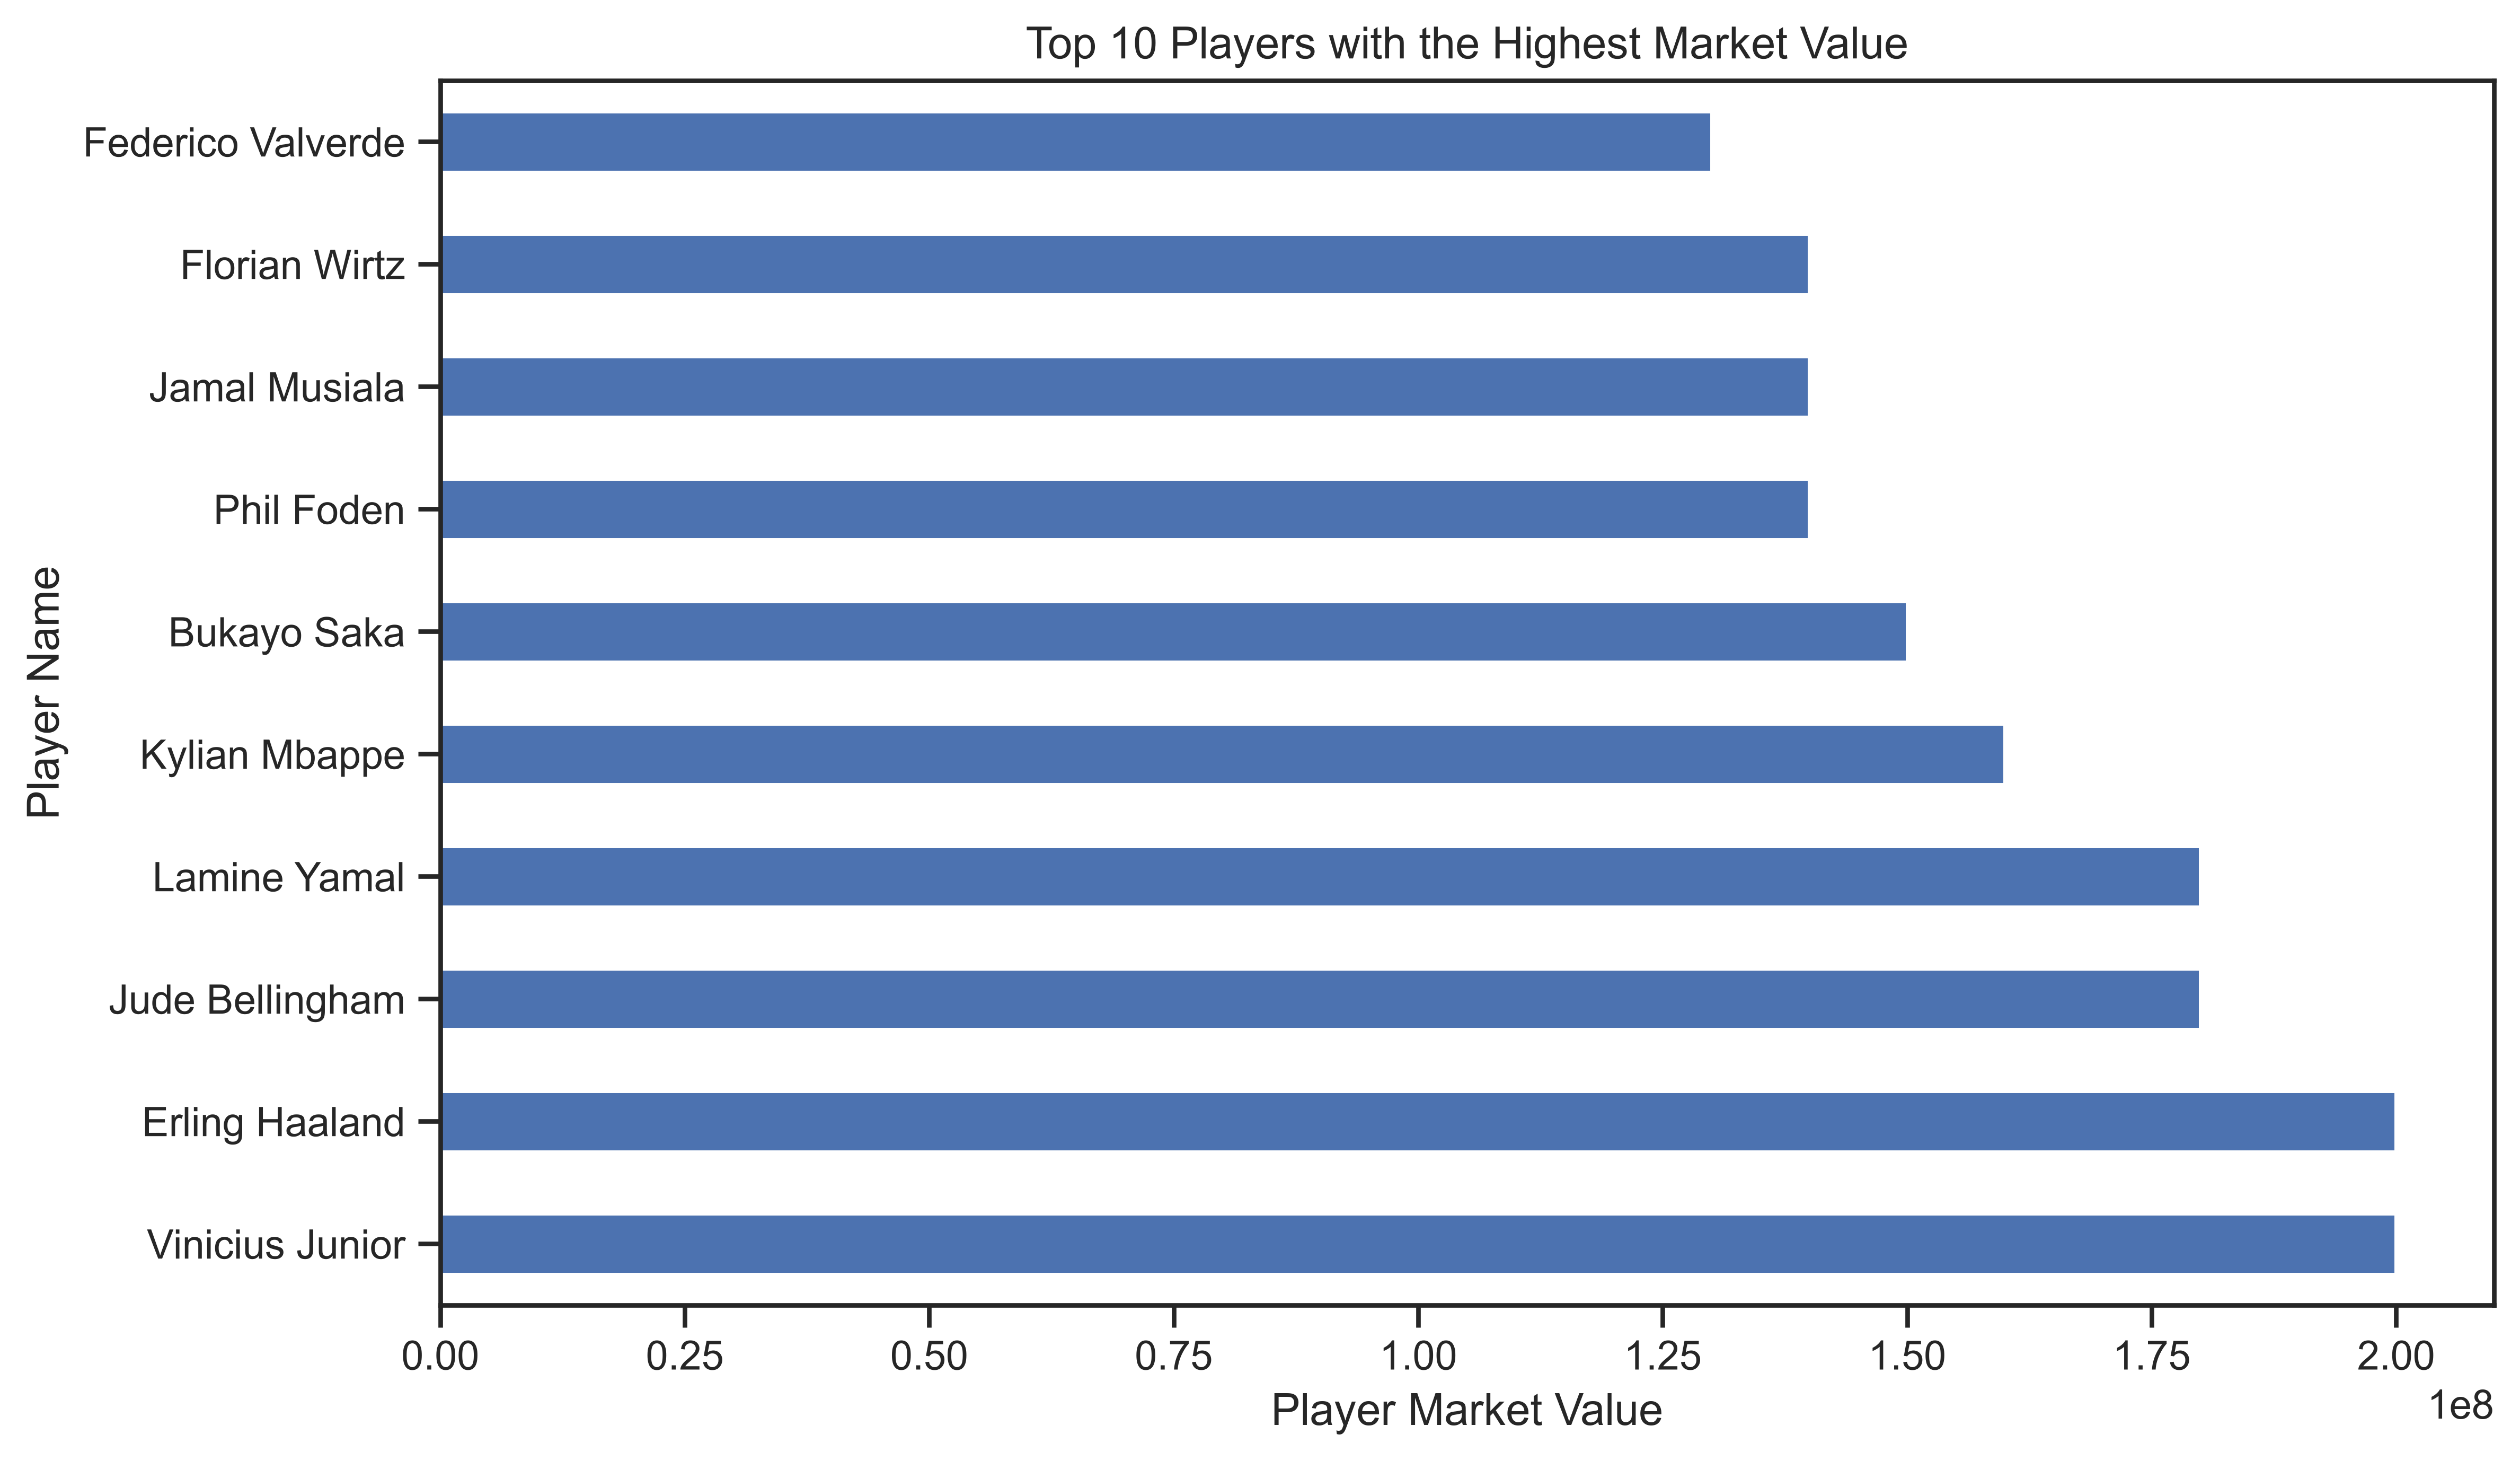

In [9]:
plt.figure(dpi=500, edgecolor='#333', figsize=(10, 6))
df.groupby('Player')['Values'].mean().sort_values(ascending=False).head(10).plot(kind='barh')

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'€{x/1e6:.0f}M')
)

plt.xlabel('Player Market Value')
plt.ylabel('Player Name')
plt.title('Top 10 Players with the Highest Market Value')   
plt.show()

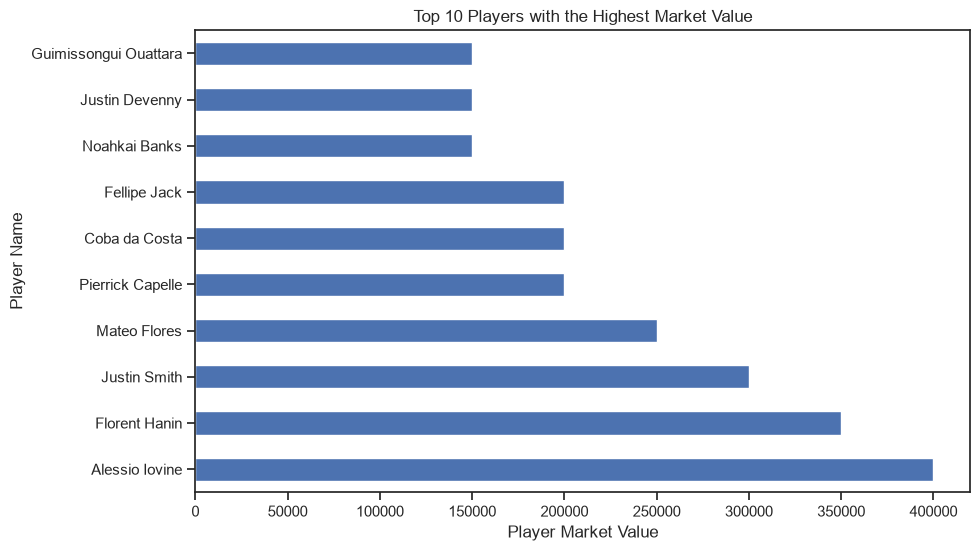

In [71]:
# players with lowest market value now
plt.figure(edgecolor='#333', figsize=(10, 6))
df.groupby('Player')['Values'].mean().sort_values(ascending=False).tail(10).plot(kind='barh')

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'€{x/1e6:.0f}M')
)

plt.xlabel('Player Market Value')
plt.ylabel('Player Name')
plt.title('Top 10 Players with the Highest Market Value')   
plt.show()

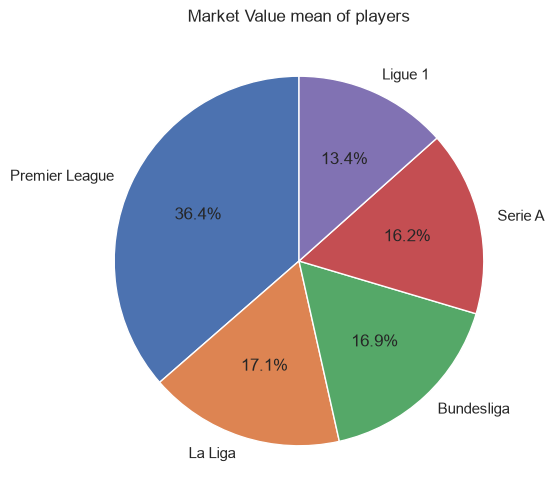

In [86]:
plt.figure(figsize=(10, 6))
df.groupby('Comp')['Values'].mean().sort_values(ascending=False).plot(kind='pie', autopct='%1.1f%%',
    startangle=90)

plt.title('Market Value mean of players')
plt.show()

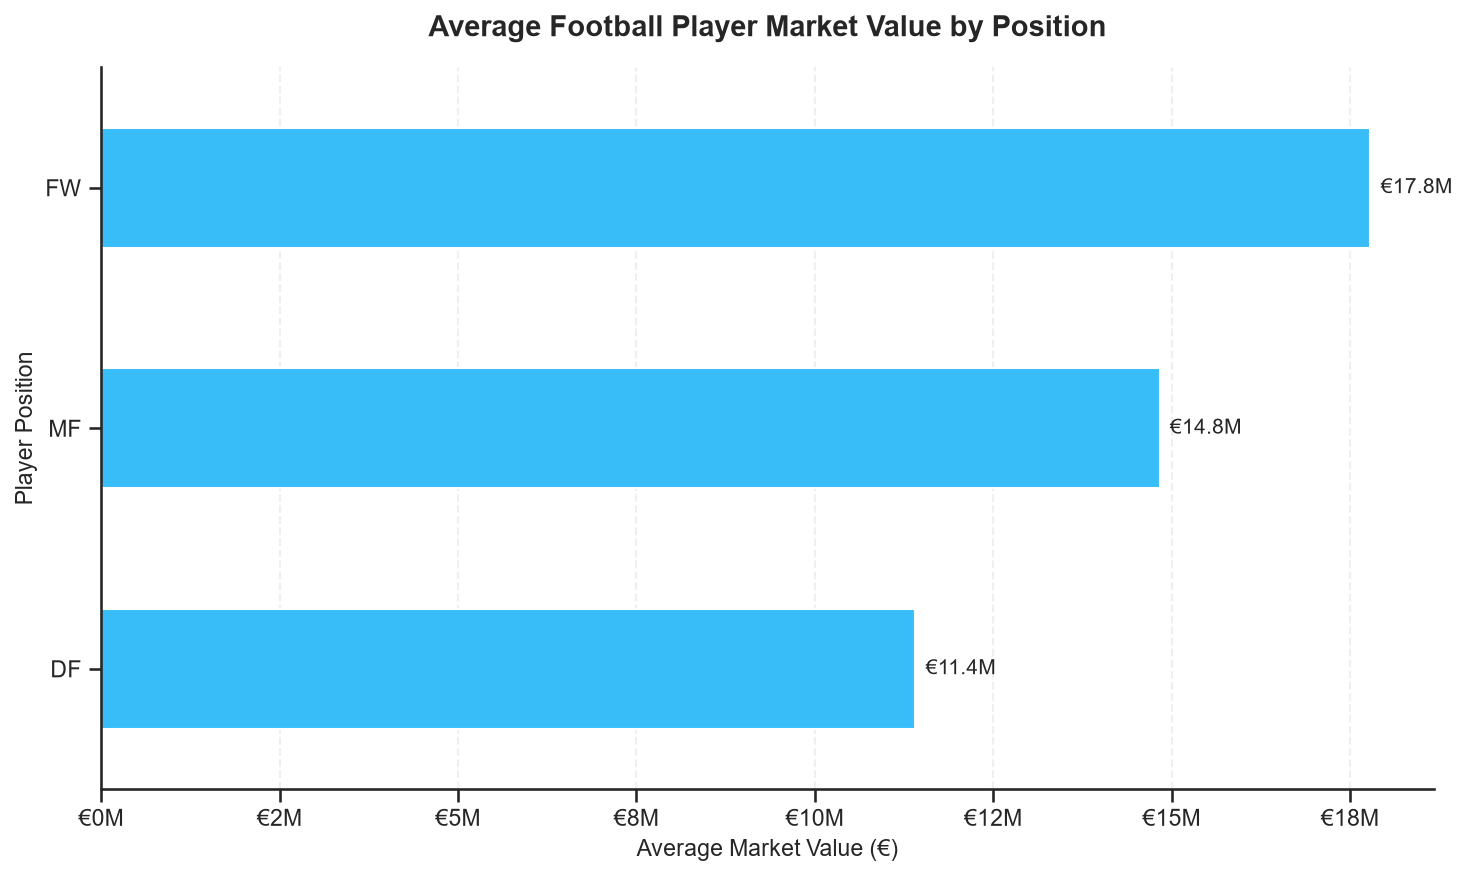

In [10]:
# Visualizing Average Player Market Value by Position
plt.figure(figsize=(10, 6), dpi=150)

ax = df.groupby('Position')['Values'].mean().sort_values().plot(
    kind='barh',
    color='#38BDF8',
    edgecolor='white',
    width=0.5
)

ax.bar_label(
    ax.containers[0],
    labels=[f'€{v/1e6:.1f}M' for v in df.groupby('Position')['Values'].mean().sort_values()],
    padding=5,
    fontsize=10
)

ax.set_xlabel('Average Market Value (€)', fontsize=11)
ax.set_ylabel('Player Position', fontsize=11)
ax.set_title(
    'Average Football Player Market Value by Position',
    fontsize=14,
    fontweight='bold',
    pad=15
)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'€{x/1e6:.0f}M')
)

ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
sns.despine()
plt.tight_layout()
plt.show()


The horizontal barchart above shows that Attackers have the highest average Market Value among other positions which is around 17.8 million. This makes sense as these are the goal scoring players who can actually turn a game in favor of the team and gets the spotlight as well. This is followed by Midfielders and Defenders with around 14.8 million and 11.4 million respectively. We will now take a look at each Player positions with respect to their Market Values.

In [113]:
# Starting by creating their seperate dataframe

defender_df = df[df['Position'] == 'DF']
midfielder_df = df[df['Position'] == 'MF']
attacker_df = df[df['Position'] == 'FW']


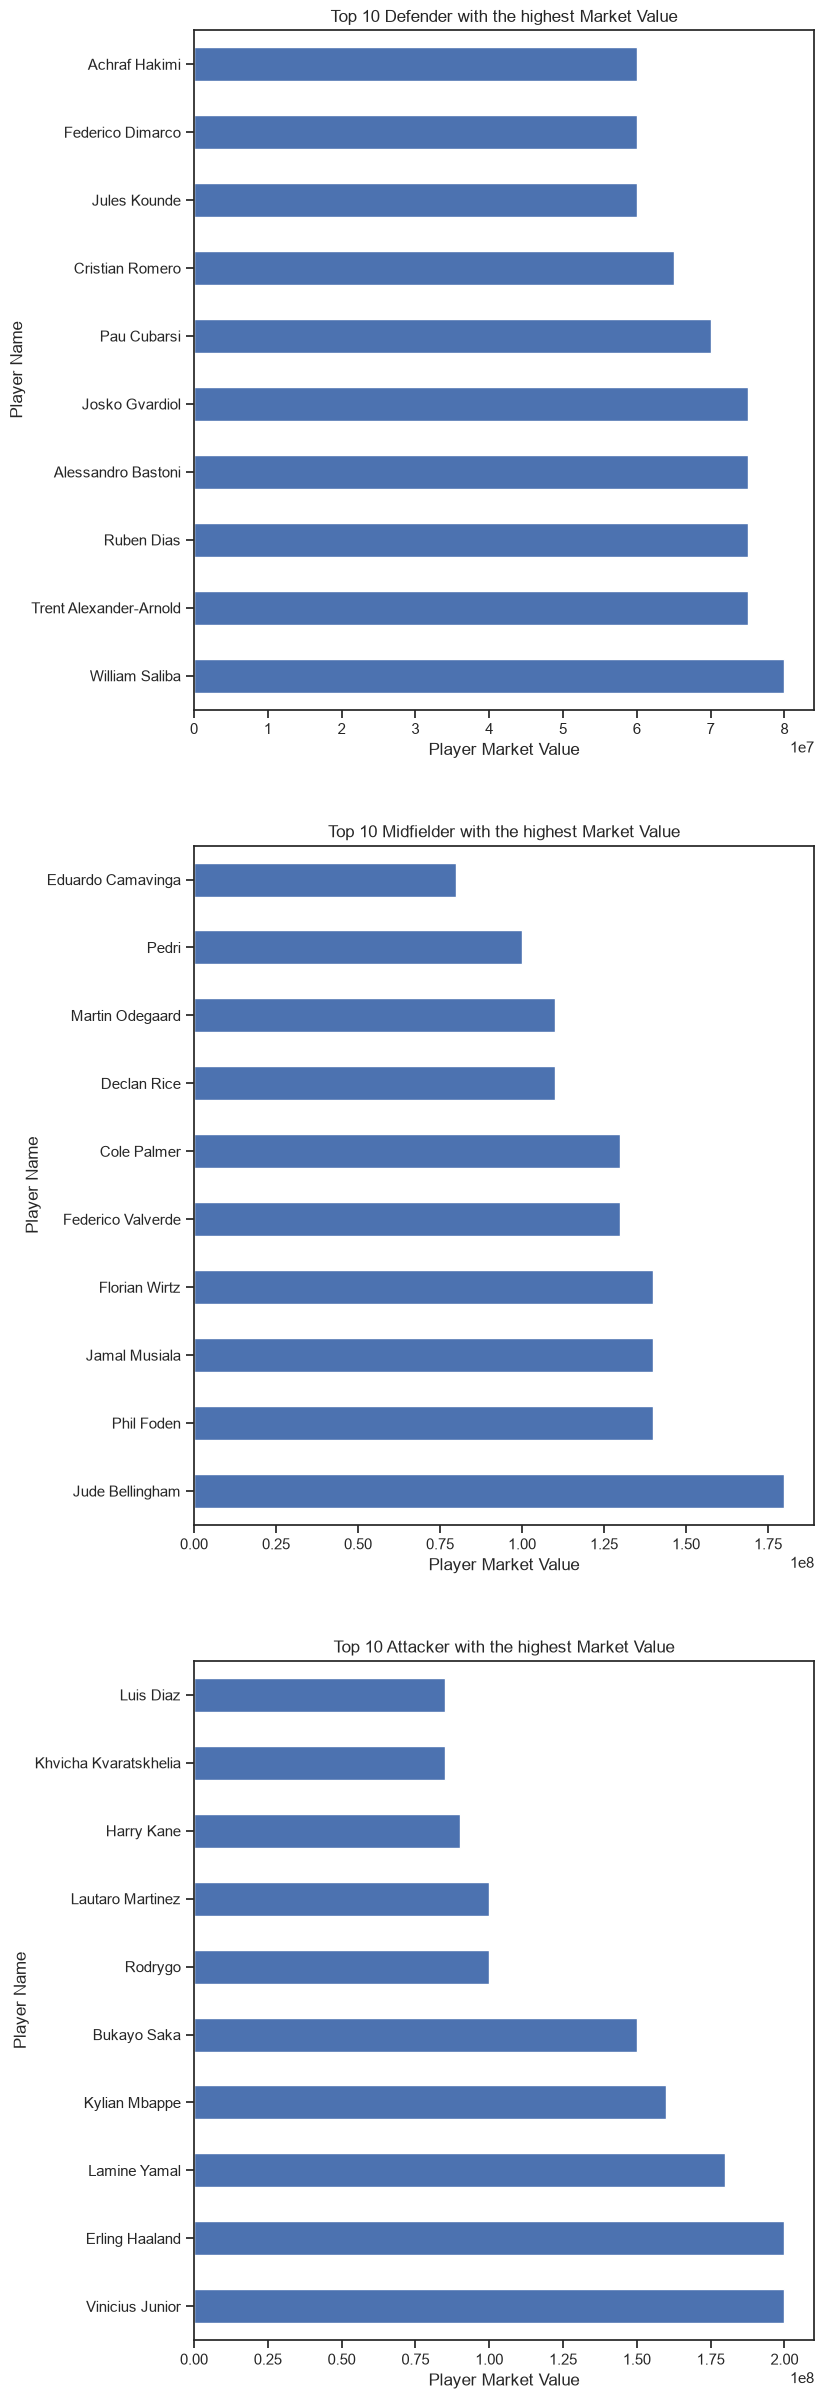

In [ ]:
# Visualizing Player positions with respect to their Market Values
plt.subplots(3, 1, figsize=(8, 30))

# Visualizing top 10 Defender with highest Market Values
plt.subplot(3, 1, 1)
defender_df.groupby(['Player'])['Values'].mean().sort_values(ascending=False).head(10).plot(kind='barh')   
plt.xlabel('Player Market Value')
plt.ylabel('Player Name')
plt.title('Top 10 Defender with the highest Market Value')

# Visualizing top 10 Midfielder with highest Market Values
plt.subplot(3, 1, 2)
midfielder_df.groupby(['Player'])['Values'].mean().sort_values(ascending=False).head(10).plot(kind='barh')   
plt.xlabel('Player Market Value')
plt.ylabel('Player Name')
plt.title('Top 10 Midfielder with the highest Market Value')

# Visualizing top 10 Attacker with highest Market Values
plt.subplot(3, 1, 3)
attacker_df.groupby(['Player'])['Values'].mean().sort_values(ascending=False).head(10).plot(kind='barh')   
plt.xlabel('Player Market Value')
plt.ylabel('Player Name')
plt.title('Top 10 Attacker with the highest Market Value')

plt.show()

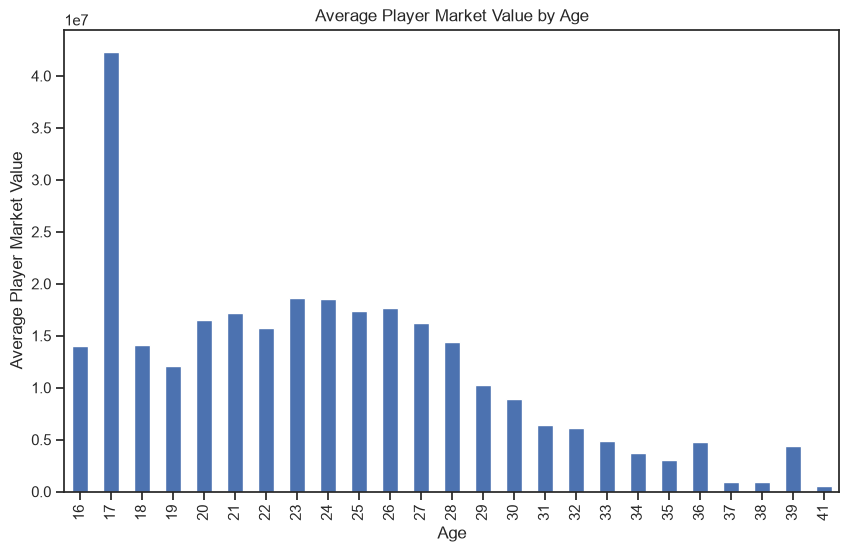

In [120]:
# Visualizing the Average Player Market Value by their Age
plt.figure(figsize=(10, 6))
df.groupby(['Age'])['Values'].mean().plot(kind='bar')
plt.xlabel('Age')
plt.ylabel('Average Player Market Value')
plt.title('Average Player Market Value by Age')
plt.show()

The chart showing the average market value of football players by age. The highest market value is at age 17, after which it generally declines with increasing age.

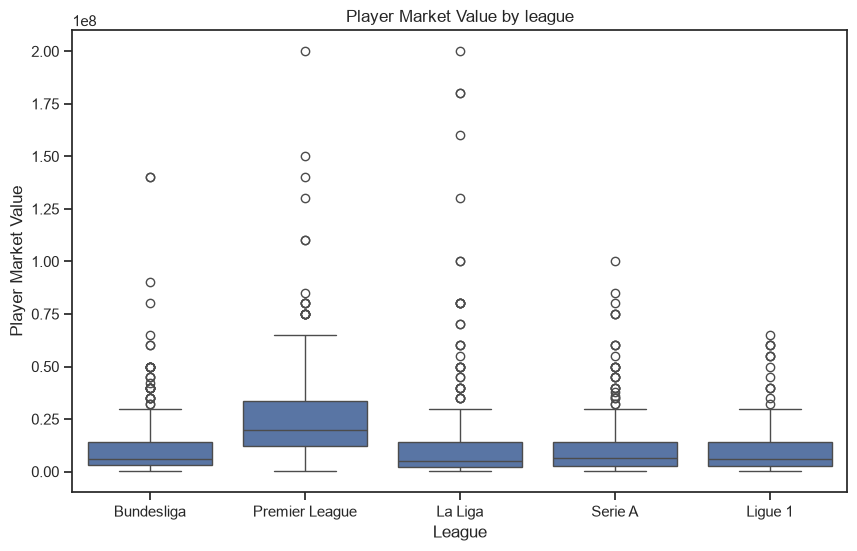

In [122]:
# relationship between league and players market value
# use a boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(x="Comp", y="Values", data=df)
plt.xlabel('League')
plt.ylabel('Player Market Value')
plt.title('Player Market Value by league')
plt.show()

In [125]:
df['Team'].nunique()

team_val = df.groupby(['Team'])['Values'].sum().sort_values(ascending=False)

team_val_df = pd.DataFrame({'Team': team_val.index, 'Total Value': team_val.values})
team_val_df.head(20)

,Team,Total Value
0,real madrid,1.177000e+09
1,manchester city,9.820000e+08
2,barcelona,9.785000e+08
3,arsenal,9.730000e+08
4,chelsea,8.760000e+08
5,bayern munich,8.140000e+08
6,liverpool,7.880000e+08
7,tottenham,7.400000e+08
8,paris s-g,7.325000e+08
9,manchester utd,7.175000e+08


Real Madrid have the highest aggregate players market value in World followed by Manchester City and Barcelona.

# Data Building

In [93]:
# create copy of dataset
data = df.copy();
data

,Player,Position,Team,Comp,Age,MP,Min,Goals,Ast,G+A,...,Clearances,Errors,Dribbles Successful,Dribble Distance,Mistakes,Ball Recoveries,Air Duels Won%,Values,Value Team,Team Value Group
0,Dominik Javorcek,DF,holstein kiel,Bundesliga,22,8,194,0,2,2,...,14,1,1,581,2,4,50.0,550000.0,44300000.0,1
1,Jesus Santiago,MF,getafe,La Liga,20,14,316,0,0,0,...,3,0,0,329,7,18,20.0,1000000.0,78200000.0,1
2,Javier Manquillo,DF,celta vigo,La Liga,30,10,515,0,0,0,...,14,0,0,1582,1,18,38.5,1800000.0,121800000.0,2
3,Ignatius Ganago,FW,nantes,Ligue 1,25,11,241,0,0,0,...,2,0,5,169,8,7,36.4,1800000.0,83000000.0,1
4,Jean-Philippe Gbamin,MF,nantes,Ligue 1,29,13,213,0,0,0,...,2,0,1,427,5,13,70.0,2000000.0,82800000.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1984,Lucas Beraldo,DF,paris s-g,Ligue 1,21,13,1085,1,0,1,...,25,1,0,6490,5,55,63.0,30000000.0,702500000.0,4
1985,Pathe Ciss,MF,rayo vallecano,La Liga,30,17,872,1,1,2,...,29,1,7,2035,9,54,61.8,2000000.0,85900000.0,1
1986,Khalil Fayad,MF,montpellier,Ligue 1,20,8,346,0,0,0,...,6,1,1,781,2,21,50.0,4000000.0,113400000.0,2
1987,Carlens Arcus,DF,angers,Ligue 1,28,19,1454,0,1,1,...,57,2,6,3406,9,58,61.5,1500000.0,42250000.0,1


In [12]:
data.columns

Index(['Player', 'Position', 'Team', 'Comp', 'Age', 'MP', 'Min', 'Goals',
       'Ast', 'G+A', 'xG', 'xA', 'SoT%', 'npxG/Sh', 'G-xG', 'Pass Cmp%',
       'Through Balls', 'Switch Passes', 'Crosses', 'Shot Creating Actions',
       'Def Action to Shot', 'Tackles', 'Shots Blocked', 'Interceptions',
       'Clearances', 'Errors', 'Dribbles Successful', 'Dribble Distance',
       'Mistakes', 'Ball Recoveries', 'Air Duels Won%', 'Values'],
      dtype='str')

In [94]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1989 entries, 0 to 1988
Data columns (total 34 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   Player                 1989 non-null   str     
 1   Position               1989 non-null   object  
 2   Team                   1989 non-null   str     
 3   Comp                   1989 non-null   str     
 4   Age                    1989 non-null   int64   
 5   MP                     1989 non-null   int64   
 6   Min                    1989 non-null   int64   
 7   Goals                  1989 non-null   int64   
 8   Ast                    1989 non-null   int64   
 9   G+A                    1989 non-null   int64   
 10  xG                     1989 non-null   float64 
 11  xA                     1989 non-null   float64 
 12  SoT%                   1989 non-null   float64 
 13  npxG/Sh                1989 non-null   float64 
 14  G-xG                   1989 non-null   float64 
 15

It converts categorical values like DF, MF, and FW into numerical columns that machine learning models can use (the code below).

In [95]:
# dummy positions
dummy_pos_grp = pd.get_dummies(data['Position'])

# adding to data frame
data = pd.concat([data, dummy_pos_grp], axis=1)

data.drop('Position', axis=1, inplace=True)

In [96]:
data.head(10)

,Player,Team,Comp,Age,MP,Min,Goals,Ast,G+A,xG,...,Dribble Distance,Mistakes,Ball Recoveries,Air Duels Won%,Values,Value Team,Team Value Group,DF,FW,MF
0,Dominik Javorcek,holstein kiel,Bundesliga,22,8,194,0,2,2,0.0,...,581,2,4,50.0,550000.0,44300000.0,1,True,False,False
1,Jesus Santiago,getafe,La Liga,20,14,316,0,0,0,0.0,...,329,7,18,20.0,1000000.0,78200000.0,1,False,False,True
2,Javier Manquillo,celta vigo,La Liga,30,10,515,0,0,0,0.0,...,1582,1,18,38.5,1800000.0,121800000.0,2,True,False,False
3,Ignatius Ganago,nantes,Ligue 1,25,11,241,0,0,0,0.4,...,169,8,7,36.4,1800000.0,83000000.0,1,False,True,False
4,Jean-Philippe Gbamin,nantes,Ligue 1,29,13,213,0,0,0,0.5,...,427,5,13,70.0,2000000.0,82800000.0,1,False,False,True
5,Adrian Beck,heidenheim,Bundesliga,27,17,565,2,1,3,1.7,...,811,14,50,70.6,2000000.0,88300000.0,1,False,False,True
6,Aridane Hernandez,rayo vallecano,La Liga,35,4,204,0,0,0,0.4,...,641,1,8,90.0,14000000.0,73900000.0,1,True,False,False
7,Marin Sverko,venezia,Serie A,26,15,1041,1,0,1,0.3,...,3788,8,42,50.0,1200000.0,85300000.0,1,True,False,False
8,Milos Kerkez,bournemouth,Premier League,21,23,1997,2,3,5,0.4,...,4214,29,102,30.2,28000000.0,332000000.0,3,True,False,False
9,Ivan Martin,girona,La Liga,25,17,1261,1,1,2,0.9,...,2645,29,75,25.0,10000000.0,197400000.0,2,False,False,True


In [97]:
# removing the unneeded columns

# player, temp, comp are not identifers they are strings and hence wont contribute in regression model
data.drop(['Player', 'Team', 'Comp'], axis=1, inplace=True)
data.head()

,Age,MP,Min,Goals,Ast,G+A,xG,xA,SoT%,npxG/Sh,...,Dribble Distance,Mistakes,Ball Recoveries,Air Duels Won%,Values,Value Team,Team Value Group,DF,FW,MF
0,22,8,194,0,2,2,0.0,0.2,0.0,0.02,...,581,2,4,50.0,550000.0,44300000.0,1,True,False,False
1,20,14,316,0,0,0,0.0,0.2,0.0,0.02,...,329,7,18,20.0,1000000.0,78200000.0,1,False,False,True
2,30,10,515,0,0,0,0.0,0.1,0.0,0.00,...,1582,1,18,38.5,1800000.0,121800000.0,2,True,False,False
3,25,11,241,0,0,0,0.4,0.1,0.0,0.06,...,169,8,7,36.4,1800000.0,83000000.0,1,False,True,False
4,29,13,213,0,0,0,0.5,0.0,0.0,0.26,...,427,5,13,70.0,2000000.0,82800000.0,1,False,False,True


All the categorical columns have been converted to numerical values and the dataset is ready for modeling. I will take a look at all the columns.

In [98]:
data.columns

Index(['Age', 'MP', 'Min', 'Goals', 'Ast', 'G+A', 'xG', 'xA', 'SoT%',
       'npxG/Sh', 'G-xG', 'Pass Cmp%', 'Through Balls', 'Switch Passes',
       'Crosses', 'Shot Creating Actions', 'Def Action to Shot', 'Tackles',
       'Shots Blocked', 'Interceptions', 'Clearances', 'Errors',
       'Dribbles Successful', 'Dribble Distance', 'Mistakes',
       'Ball Recoveries', 'Air Duels Won%', 'Values', 'Value Team',
       'Team Value Group', 'DF', 'FW', 'MF'],
      dtype='str')

In [99]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1989 entries, 0 to 1988
Data columns (total 33 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   Age                    1989 non-null   int64   
 1   MP                     1989 non-null   int64   
 2   Min                    1989 non-null   int64   
 3   Goals                  1989 non-null   int64   
 4   Ast                    1989 non-null   int64   
 5   G+A                    1989 non-null   int64   
 6   xG                     1989 non-null   float64 
 7   xA                     1989 non-null   float64 
 8   SoT%                   1989 non-null   float64 
 9   npxG/Sh                1989 non-null   float64 
 10  G-xG                   1989 non-null   float64 
 11  Pass Cmp%              1989 non-null   float64 
 12  Through Balls          1989 non-null   int64   
 13  Switch Passes          1989 non-null   int64   
 14  Crosses                1989 non-null   int64   
 15

In [100]:
corr_X = data.corr();
corr_X

,Age,MP,Min,Goals,Ast,G+A,xG,xA,SoT%,npxG/Sh,...,Dribble Distance,Mistakes,Ball Recoveries,Air Duels Won%,Values,Value Team,Team Value Group,DF,FW,MF
Age,1.000000,0.081440,0.101098,0.002428,0.015802,0.008649,0.023799,0.044676,-0.034413,0.044536,...,0.169972,-0.096165,0.057245,0.114517,-0.197502,-0.044177,-0.046413,0.079070,-0.041770,-0.043477
MP,0.081440,1.000000,0.857184,0.392349,0.421799,0.465485,0.425301,0.507785,0.128314,0.132732,...,0.477245,0.614897,0.722274,-0.014449,0.260350,0.070317,0.080055,-0.139577,0.106914,0.046302
Min,0.101098,0.857184,1.000000,0.363704,0.407152,0.438562,0.376722,0.509085,0.071408,0.049294,...,0.696378,0.558429,0.850237,0.102202,0.298784,0.055931,0.064216,0.093503,-0.077308,-0.025801
Goals,0.002428,0.392349,0.363704,1.000000,0.472024,0.922705,0.894896,0.454593,0.302192,0.333588,...,-0.086669,0.638056,0.139128,-0.119781,0.436740,0.154346,0.152213,-0.324468,0.437224,-0.065496
Ast,0.015802,0.421799,0.407152,0.472024,1.000000,0.775397,0.484608,0.724114,0.122775,0.103031,...,0.115879,0.515367,0.339624,-0.136949,0.422912,0.206917,0.209113,-0.219516,0.211996,0.032585
G+A,0.008649,0.465485,0.438562,0.922705,0.775397,1.000000,0.852922,0.642269,0.270147,0.284002,...,-0.011408,0.682400,0.248171,-0.145754,0.497769,0.201040,0.200472,-0.328406,0.405885,-0.032665
xG,0.023799,0.425301,0.376722,0.894896,0.484608,0.852922,1.000000,0.443977,0.248526,0.411347,...,-0.112232,0.678145,0.130045,-0.117818,0.430697,0.157338,0.160607,-0.368904,0.496064,-0.073513
xA,0.044676,0.507785,0.509085,0.454593,0.724114,0.642269,0.443977,1.000000,0.137676,0.036095,...,0.239459,0.558722,0.490167,-0.154030,0.433694,0.201164,0.207571,-0.213429,0.141034,0.091401
SoT%,-0.034413,0.128314,0.071408,0.302192,0.122775,0.270147,0.248526,0.137676,1.000000,0.357511,...,-0.055871,0.183743,0.015749,-0.082110,0.109707,0.041844,0.045185,-0.149937,0.212877,-0.040208
npxG/Sh,0.044536,0.132732,0.049294,0.333588,0.103031,0.284002,0.411347,0.036095,0.357511,1.000000,...,-0.101066,0.177305,-0.055703,-0.024966,0.119137,0.102175,0.098036,-0.167729,0.307579,-0.108696


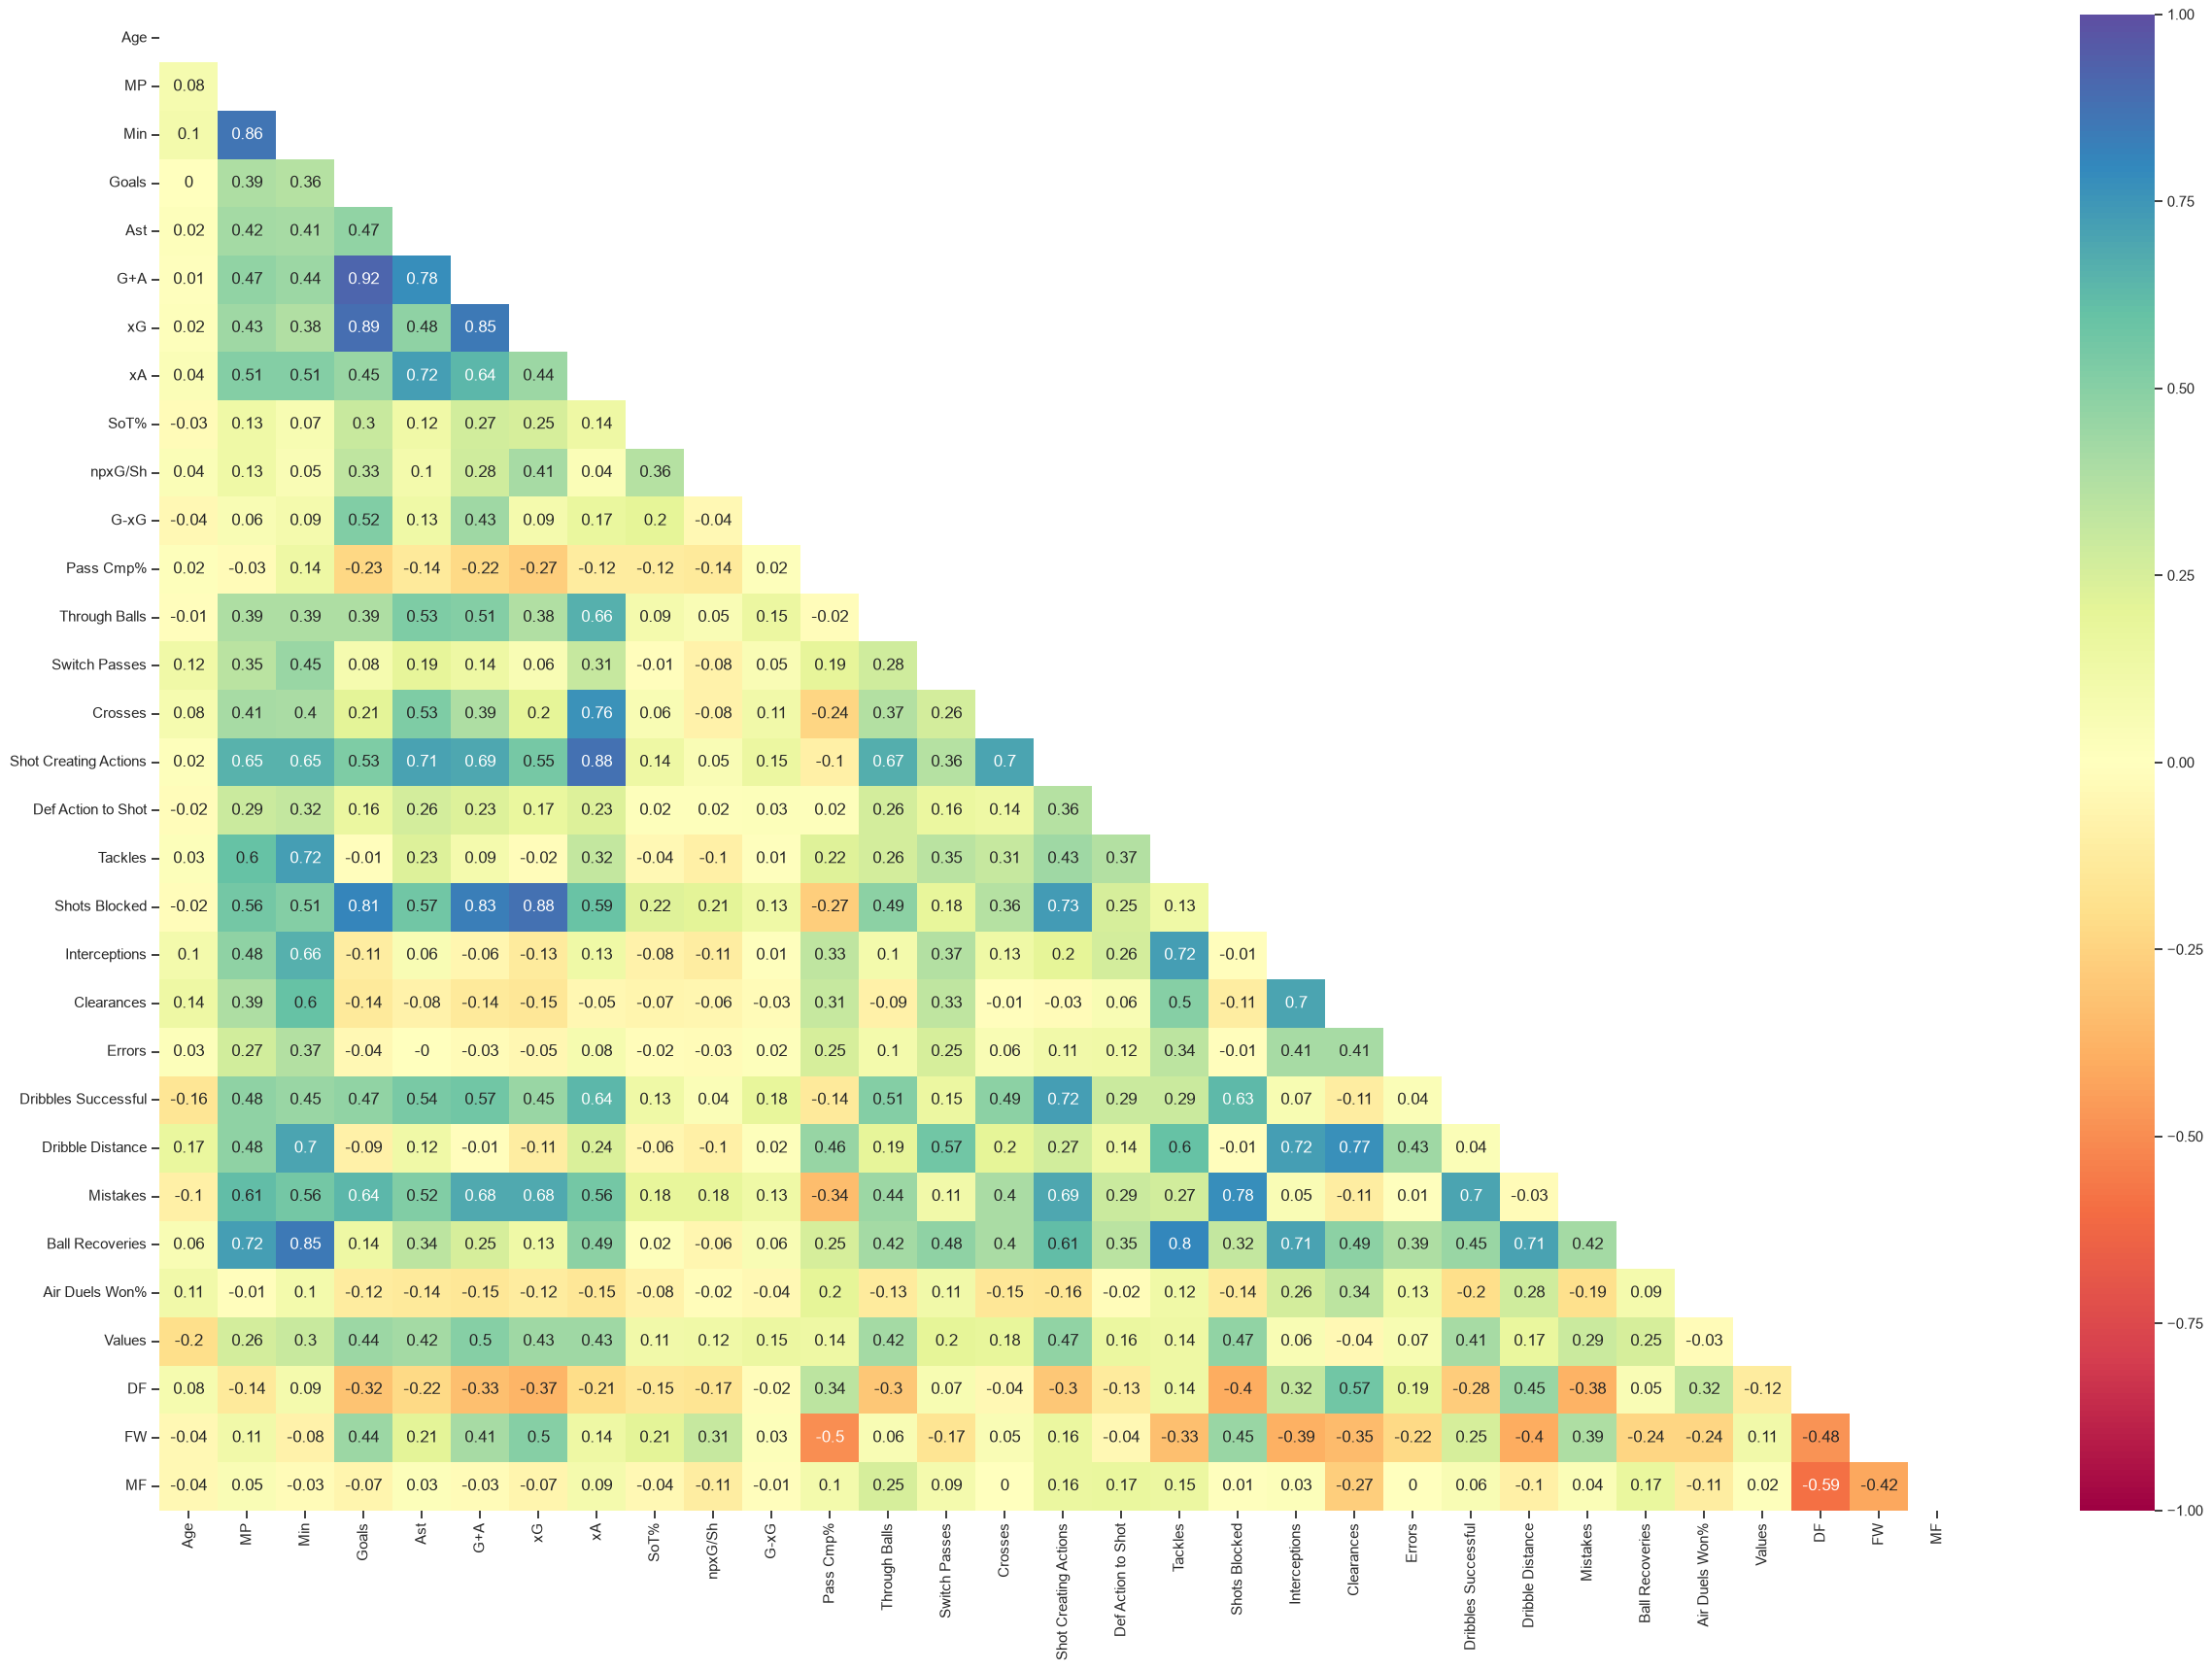

In [155]:
# Creating heatmapp
mask = np.triu(corr_X)      # uppar trinagular matrix

plt.figure(figsize=(30, 20))
sns.heatmap(corr_X.round(2), annot=True, vmax=1, vmin=-1, center=0, cmap='Spectral', mask=mask)
plt.show()

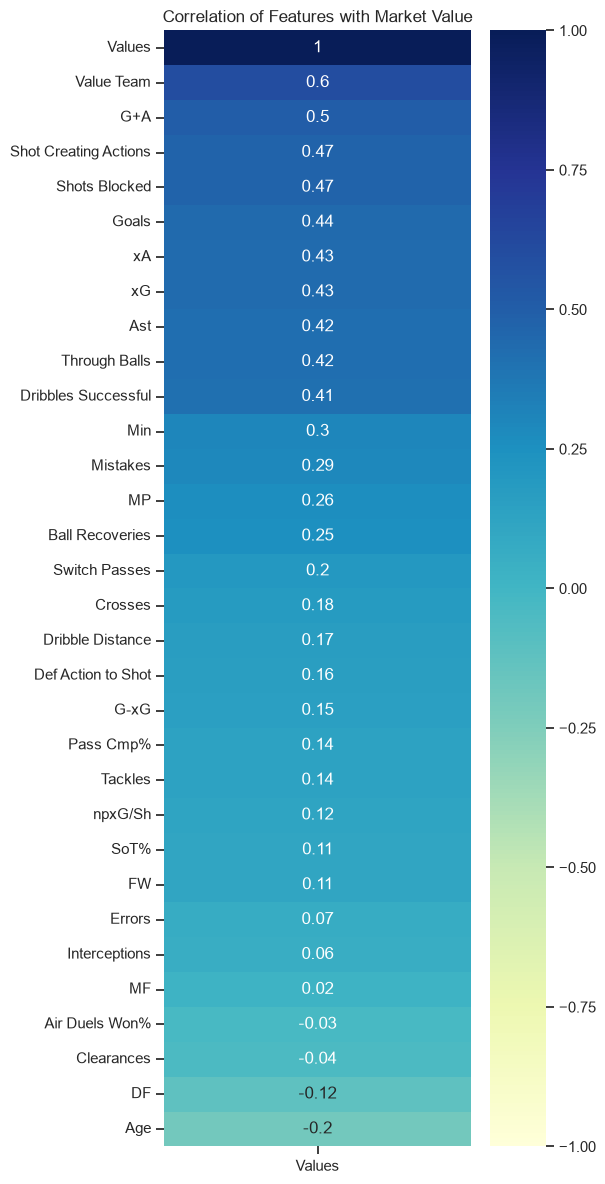

In [101]:
# correlation to the values only
corr_values = data.corr(numeric_only=True)['Values'].sort_values(ascending=False)

plt.figure(figsize=(6, 12))
sns.heatmap(
    corr_values.to_frame().round(2),
    annot=True,
    cmap='YlGnBu',
    vmin=-1,
    vmax=1,
    center=0
)
plt.title('Correlation of Features with Market Value')
plt.tight_layout()
plt.show()

In [102]:
# features and target
X = data.drop(columns=["Values"])
y = data["Values"]

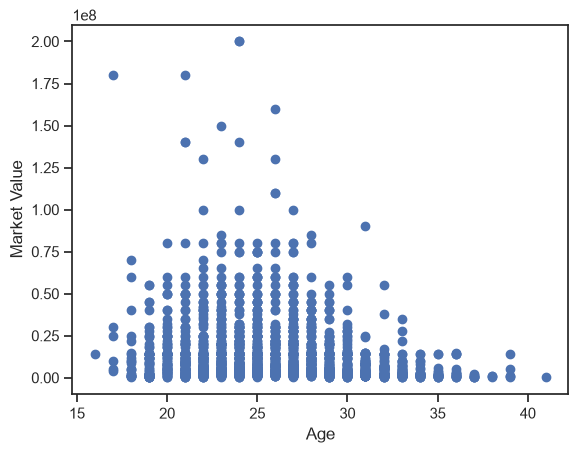

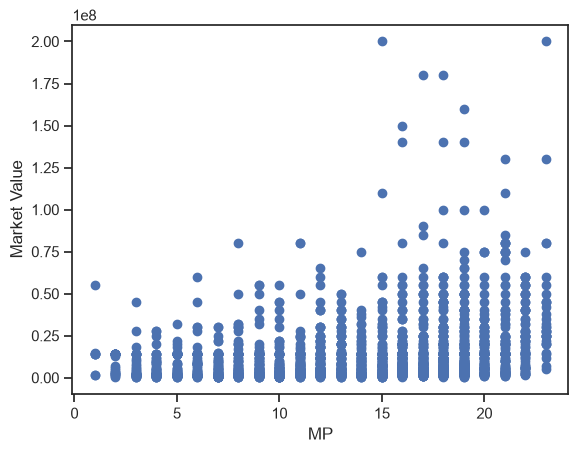

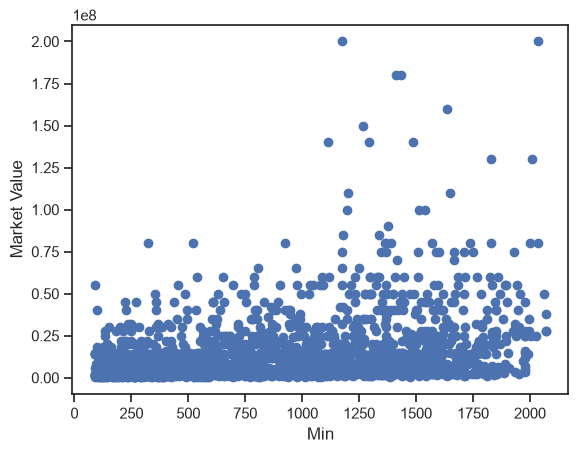

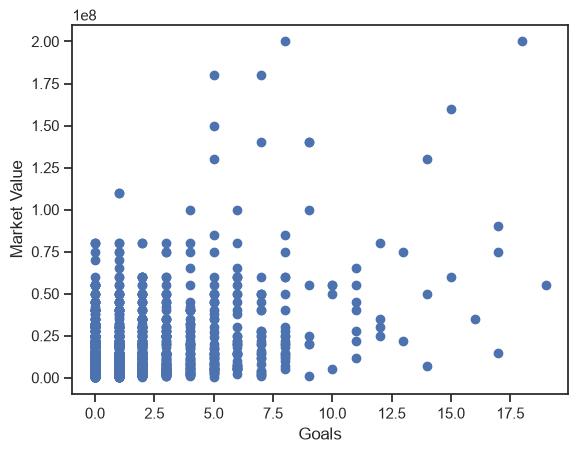

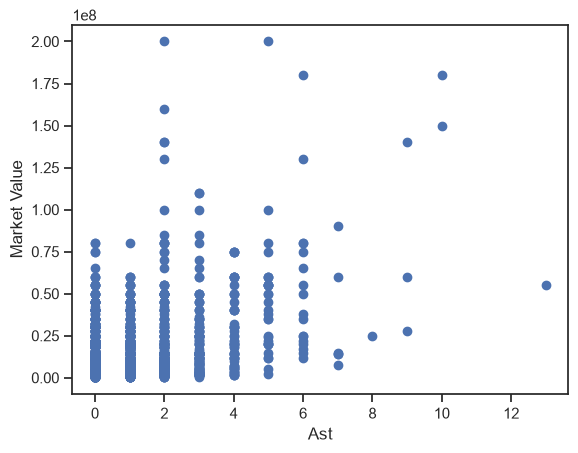

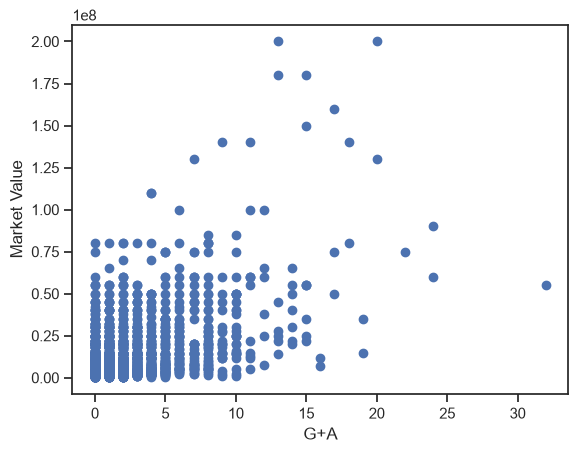

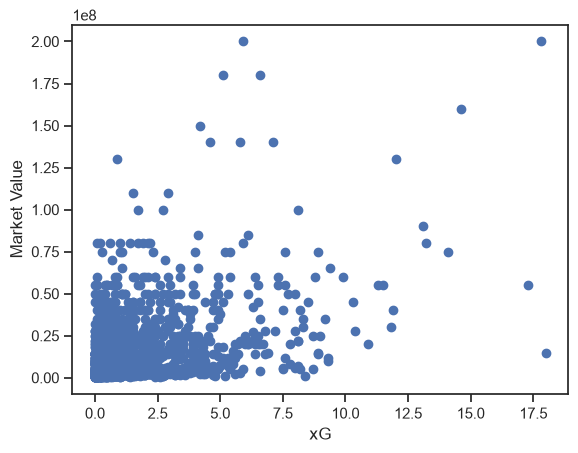

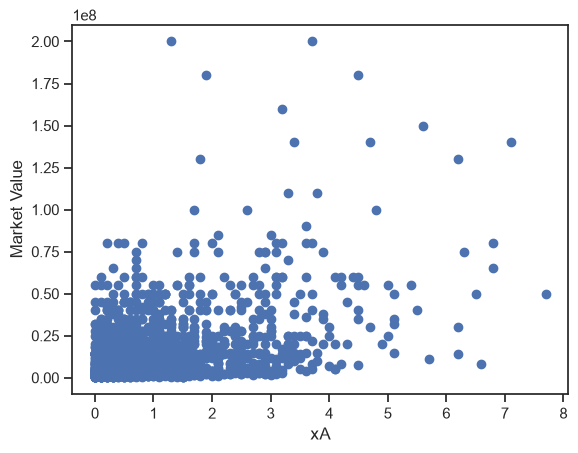

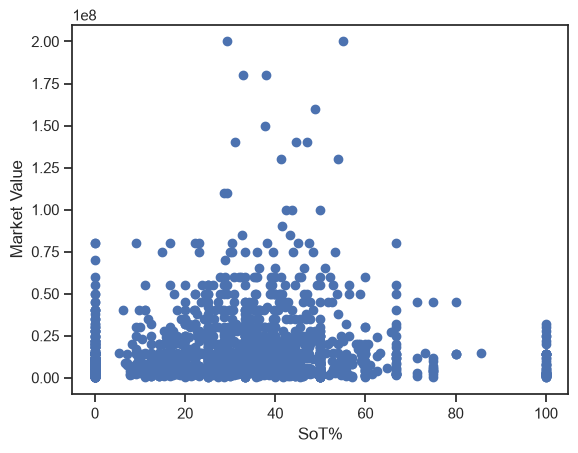

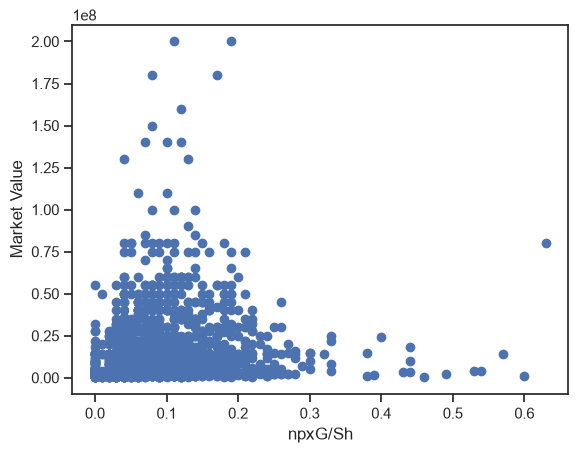

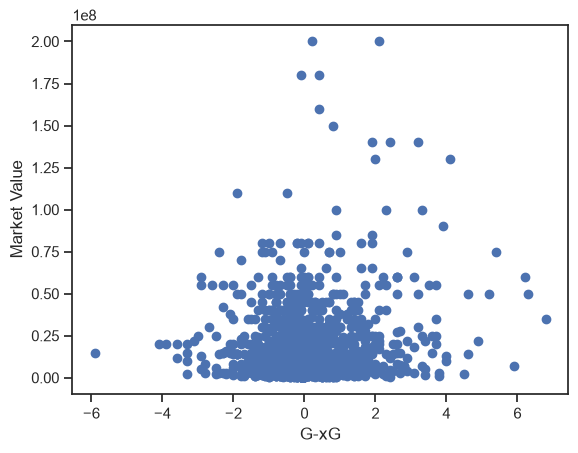

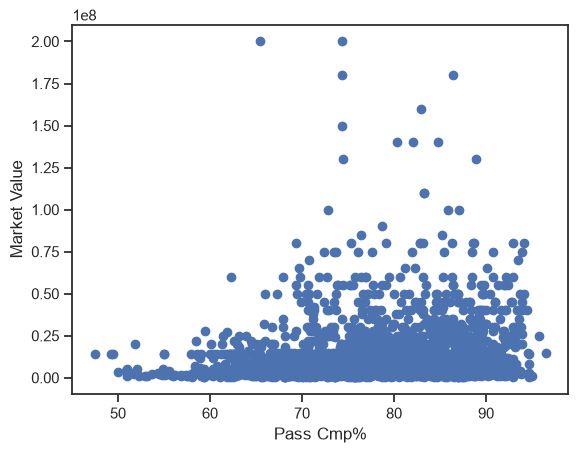

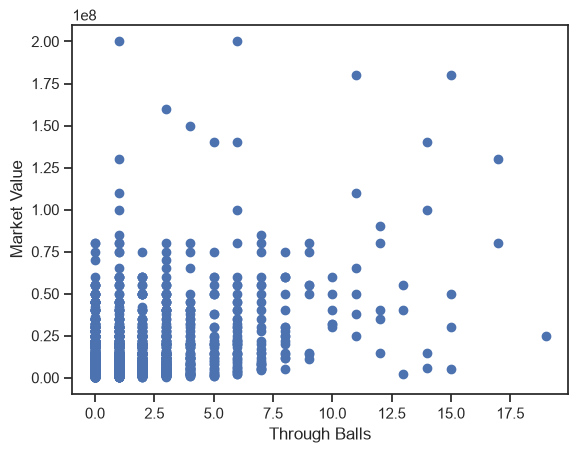

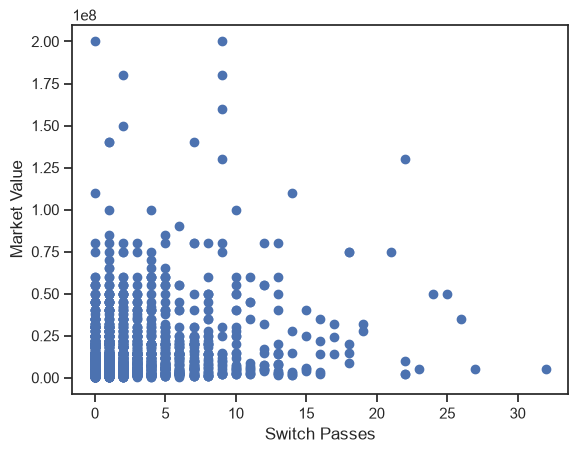

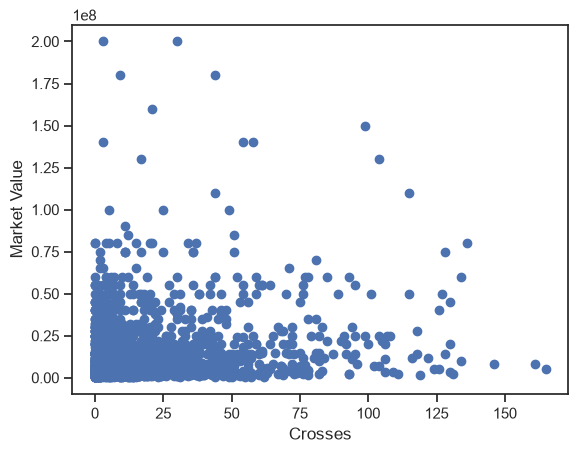

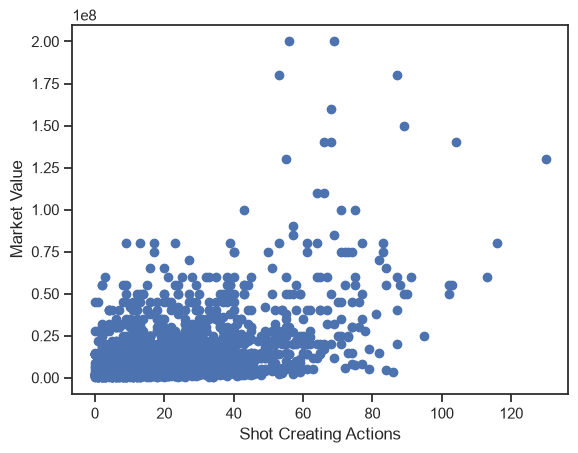

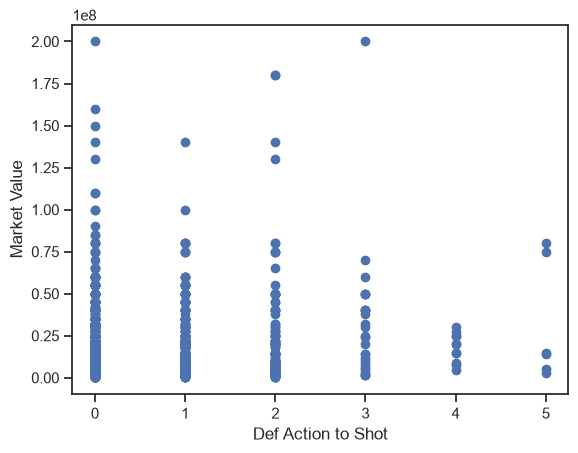

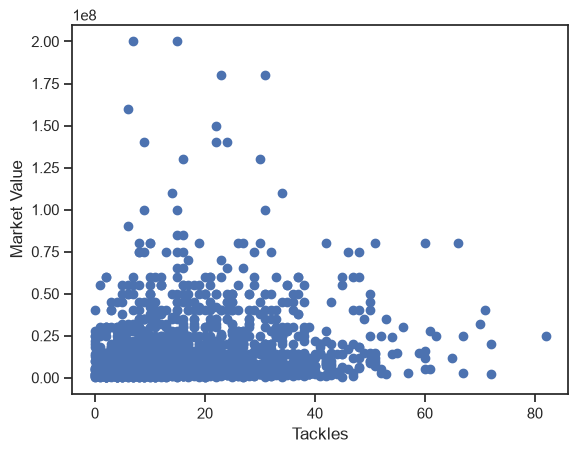

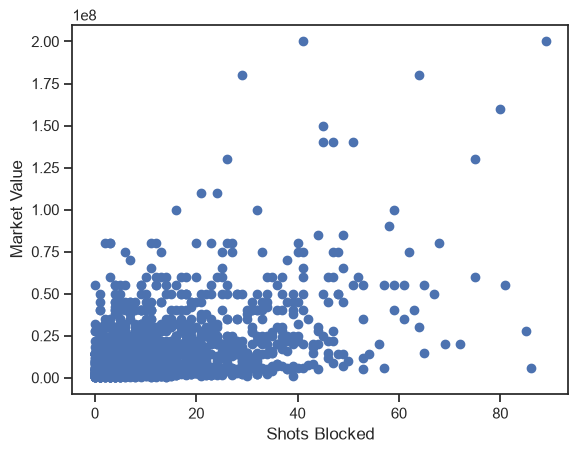

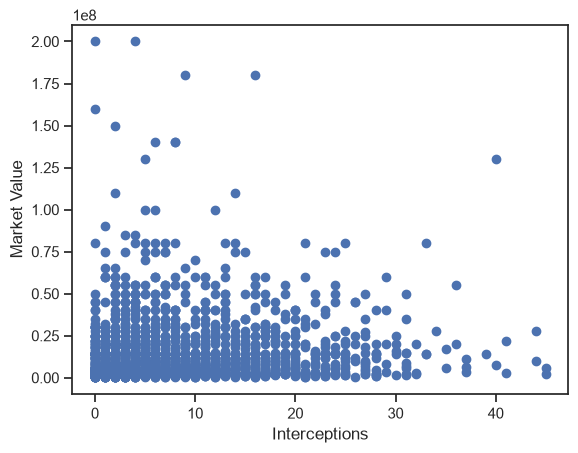

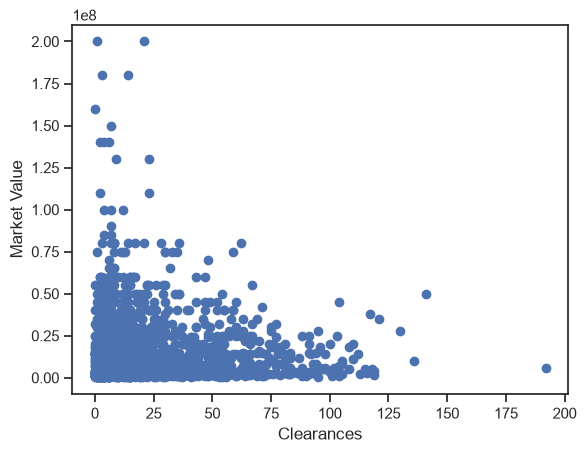

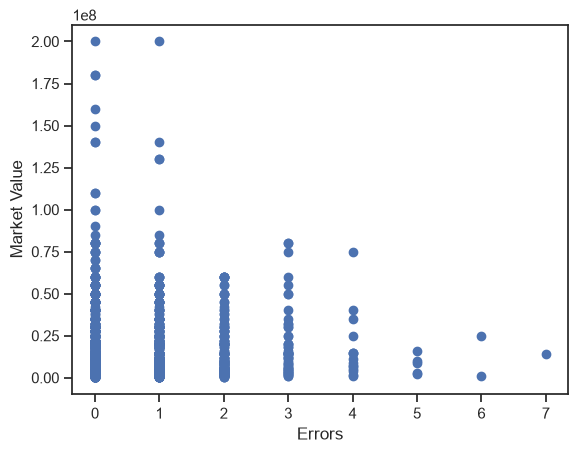

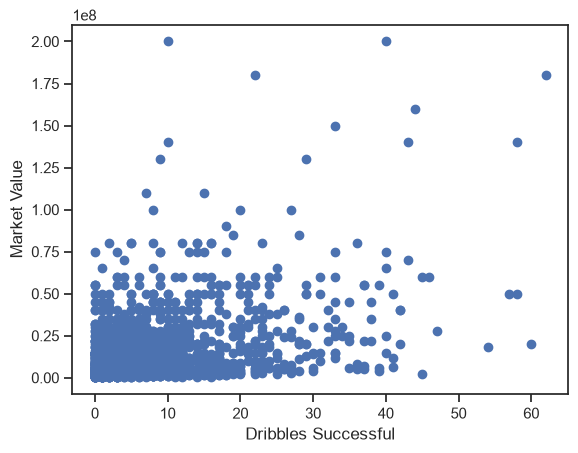

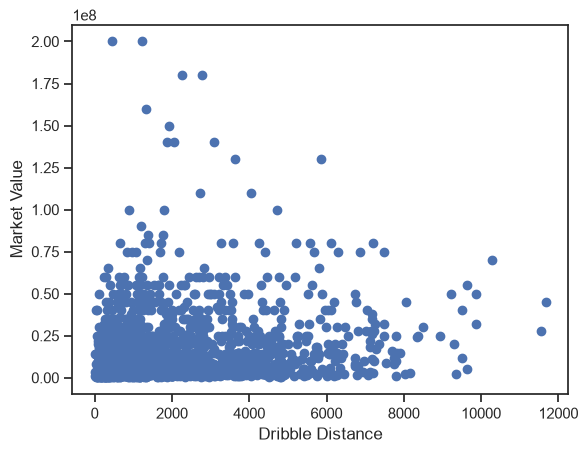

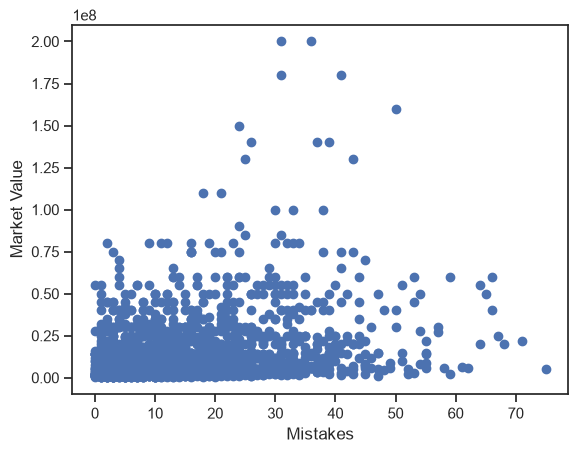

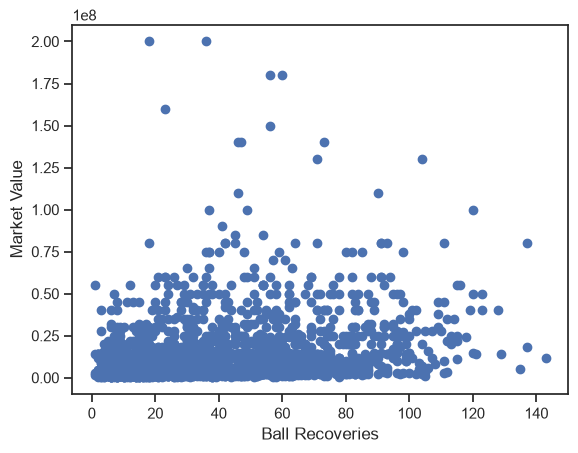

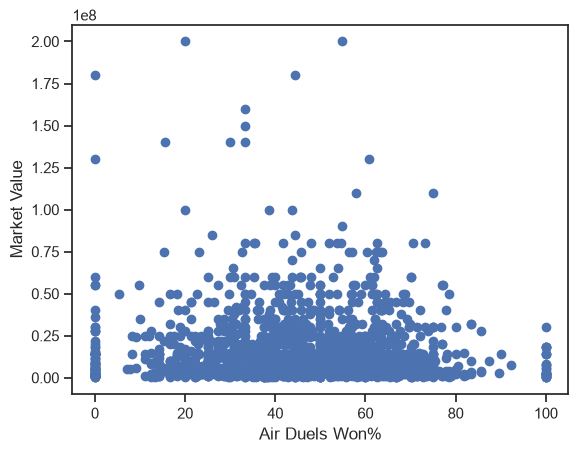

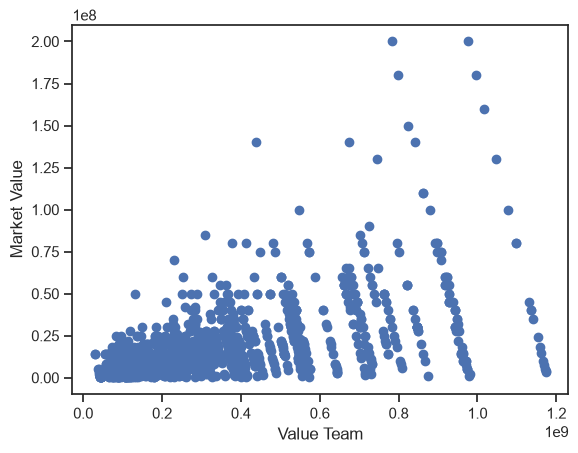

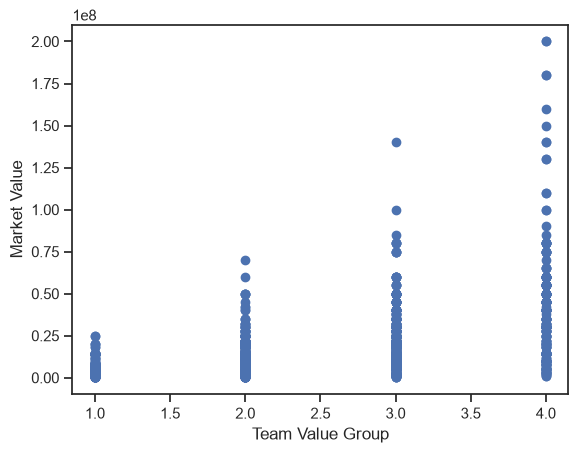

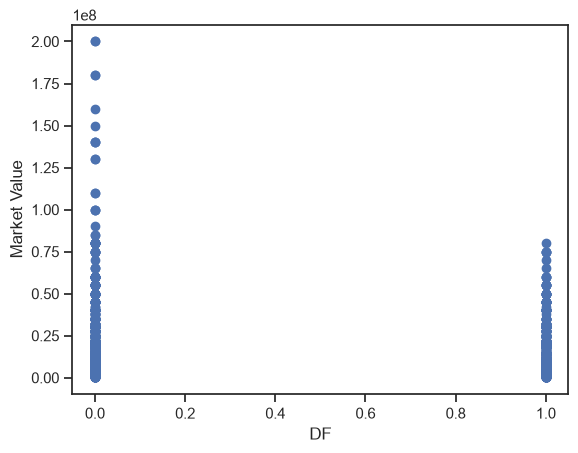

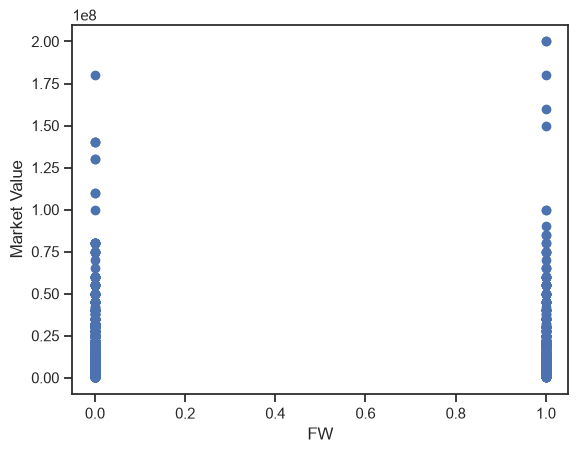

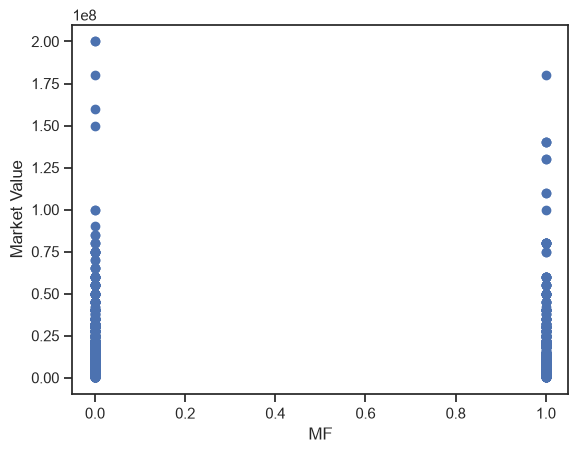

In [103]:
# variables vs market value

for col in X.columns: 
    plt.figure()
    plt.scatter(X[col], y)
    plt.ylabel('Market Value')
    plt.xlabel(col)
    
    plt.show()

In [104]:
# Libraries for modeling

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, RobustScaler

from sklearn.linear_model import LinearRegression

In [105]:
df1 = data.copy()
mask = data['Values'] > 0   # values greater than 0
df1['Values'] = np.where(mask, np.log(data.loc[mask, 'Values']), np.nan) 

Storing the log values instead of values directly because some of the superstars have extremely high values.

In [106]:
# Rename 'Values' column for clarity
df1 = df1.rename(columns={'Values': 'Log Market Value'})

In [107]:
# one-Hot Encoding for position
df1['Is_Defender'] = (df1['DF'] > 0).astype(int)
df1['Is_Forward'] = (df1['FW'] > 0).astype(int)
df1['Is_Midfielder'] = (df1['MF'] > 0).astype(int)


# feature engineering
df1['Goals_per_MP'] = df1['Goals'] / df1['MP']
df1['Assists_per_MP'] = df1['Ast'] / df1['MP']
df1['Shot_Creating_Actions_per_MP'] = df1['Shot Creating Actions'] / df1['MP']
df1['Through_Balls_per_MP'] = df1['Through Balls'] / df1['MP']
df1['Dribbles_Successful_per_MP'] = df1['Dribbles Successful'] / df1['MP']
df1['Offensive_Index'] = df1['Goals'] + df1['Ast'] + 0.5 * df1['Shot Creating Actions']

In [108]:
# list of features
features = [
    'Min',
    'Goals',
    'Ast',
    'xA',
    'xG',
    'G+A',
    'Through Balls',
    'Dribbles Successful',
    'Ball Recoveries',
    'Age',
    'Shots Blocked',
    'Value Team',   
    'Shot Creating Actions',
    'Goals_per_MP',
    'Assists_per_MP',
    'Shot_Creating_Actions_per_MP',
    'Through_Balls_per_MP',
    'Dribbles_Successful_per_MP',
    'Offensive_Index'
    # 'Matches',
    # 'MP'
    ]

In [109]:
# drop the not needed columns
columns_to_drop = [
    'Matches', 'MP',
    'SoT%', 'Dribble Distance','npxG/Sh','Crosses','Tackles','Interceptions','Dribble Distance','Air Duels Won%',
    'Pass Cmp%', 'Switch Passes', 'Def Action to Shot', 
    'Clearances', 'Errors', 'DF', 'FW', 'MF', 'Values', 'Crosses'
]

df1.drop([col for col in columns_to_drop if col in df1.columns], axis=1, errors='ignore', inplace=True)

In [110]:
features = [col for col in features if col in df1.columns]

X = df1[features]
y = df1['Log Market Value']

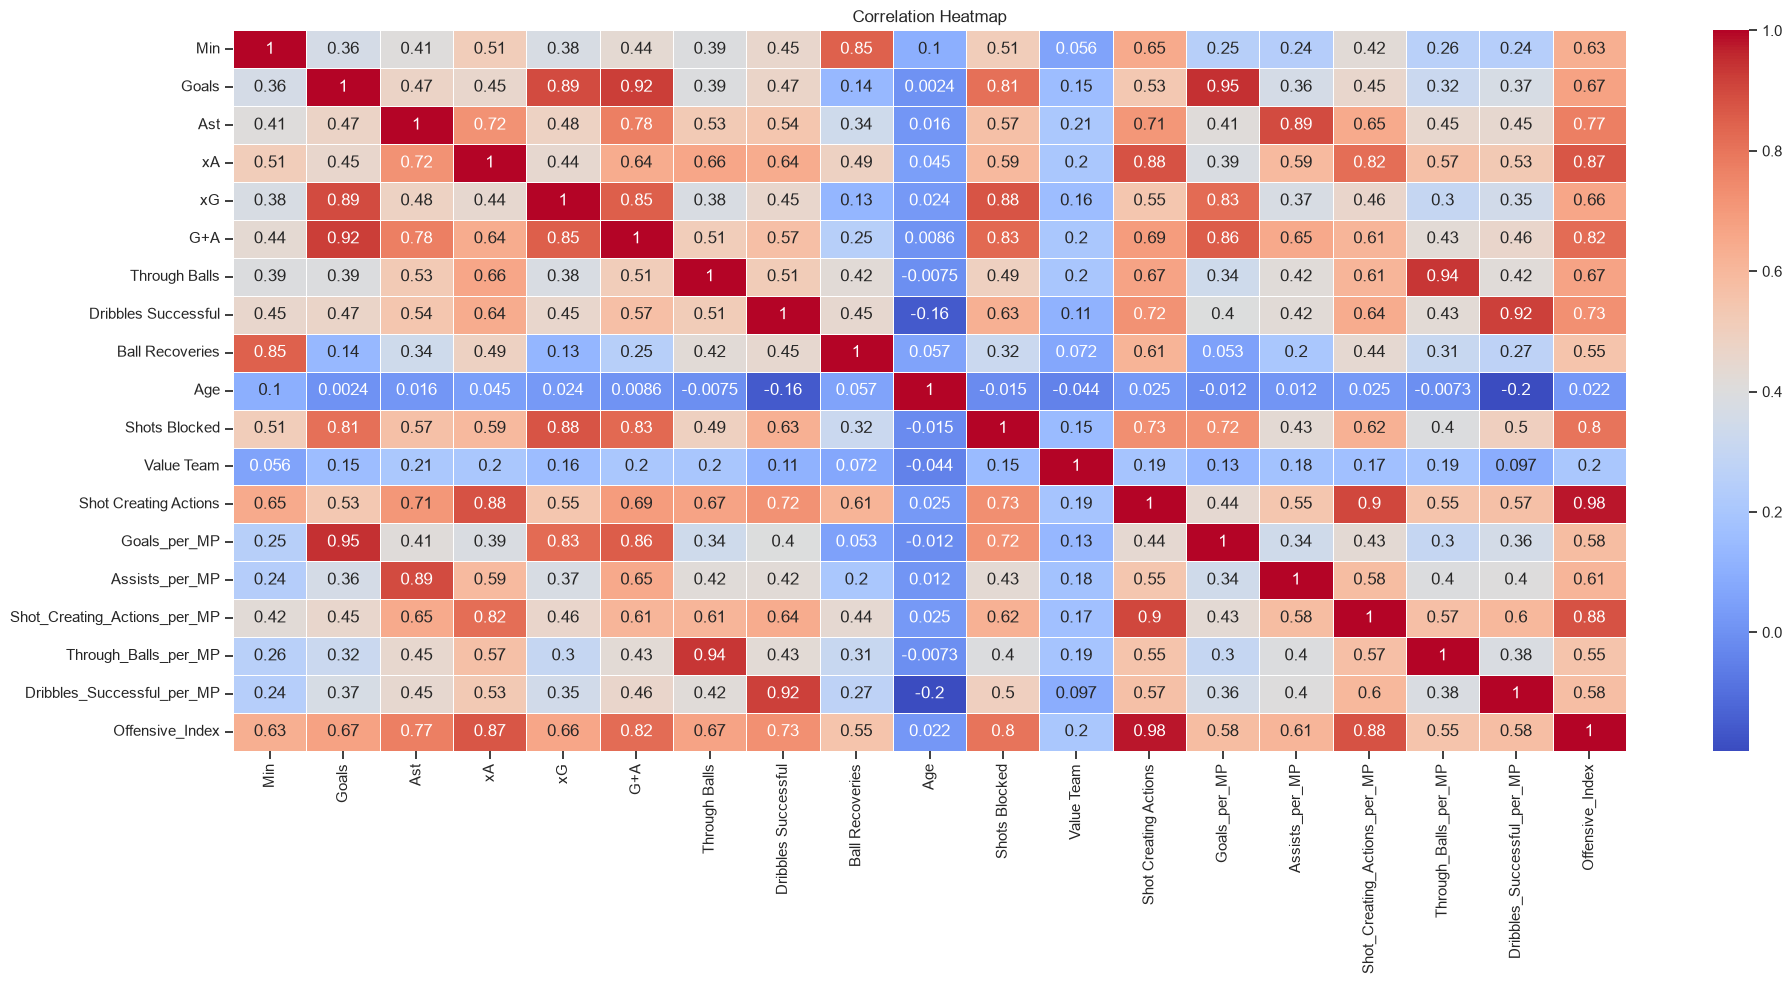

In [111]:
# all features after feature engineering in heatmap

plt.figure(figsize=(20, 10))
sns.heatmap(X.corr(), annot=True, cmap="coolwarm", linewidths=.5)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [112]:
# Split the data into training, validation, and test sets

# train - training
# val - validation
# test - testing

X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.25, random_state=42)

In [113]:
# numerical and categorical features

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = ['Is_Defender', 'Is_Forward', 'Is_Midfielder']  

In [114]:

# checking for missing values - just in case

print(X.isnull().sum().sort_values(ascending=False).head(15))
print("Missing target values:", y.isnull().sum())

Min                      0
Goals                    0
Ast                      0
xA                       0
xG                       0
G+A                      0
Through Balls            0
Dribbles Successful      0
Ball Recoveries          0
Age                      0
Shots Blocked            0
Value Team               0
Shot Creating Actions    0
Goals_per_MP             0
Assists_per_MP           0
dtype: int64
Missing target values: 0


### Multiple Linear Regression

In [115]:
# Training the model
lr_model = LinearRegression();
lr_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](19,)","[0.,0.,0.,...,0.,0.,0.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](19,)","['Min','Goals','Ast',...,'Through_Balls_per_MP', 'Dribbles_Successful_per_MP','Offensive_Index']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,14.32
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,19
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [116]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
y_pred = lr_model.predict(X_val)

# predicting on validation data
print("MAE:", mean_absolute_error(y_val, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_val, y_pred)))
print("R²:", r2_score(y_val, y_pred))

MAE: 0.7311240202391489
RMSE: 0.9084691338750327
R²: 0.4429440328039551


In [117]:
y_train_pred = lr_model.predict(X_train)

print("Training R²:", r2_score(y_train, y_train_pred))
print("Validation R²:", r2_score(y_val, y_pred))

print("Training MAE:", mean_absolute_error(y_train, y_train_pred))
print("Validation MAE:", mean_absolute_error(y_val, y_pred))

Training R²: 0.42782719932518554
Validation R²: 0.4429440328039551
Training MAE: 0.7491337365003436
Validation MAE: 0.7311240202391489


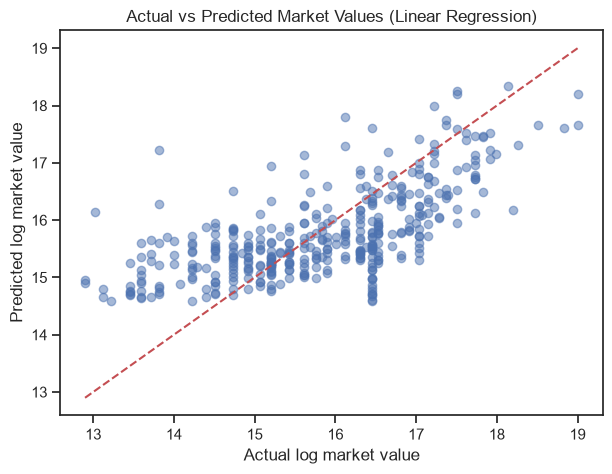

In [152]:
plt.figure(figsize=(7, 5))
plt.scatter(y_val, y_pred, alpha=0.5)

plt.xlabel("Actual log market value")
plt.ylabel("Predicted log market value")
plt.title("Actual vs Predicted Market Values (Linear Regression)")

lower = min(y_val.min(), y_pred.min())
upper = max(y_val.max(), y_pred.max())

plt.plot([lower, upper], [lower, upper], "r--")
plt.show()

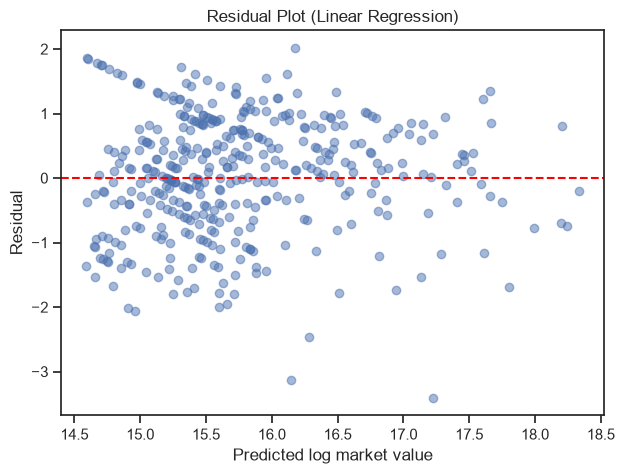

In [153]:
residuals = y_val - y_pred

plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted log market value")
plt.ylabel("Residual")
plt.title("Residual Plot (Linear Regression)")
plt.show()

### Random Forest

In [149]:
from sklearn.ensemble import RandomForestRegressor

# training the data
rf_regressor = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_regressor.fit(X_train, y_train)

y_pred_rf = rf_regressor.predict(X_val)

print("MAE:", mean_absolute_error(y_val, y_pred_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_val, y_pred_rf)))
print("R²:", r2_score(y_val, y_pred_rf))

MAE: 0.543829638276191
RMSE: 0.7088571032620137
R²: 0.6608468387699429


In [148]:
y_train_pred_rf = rf_regressor.predict(X_train)

print("Training R²:", r2_score(y_train, y_train_pred_rf))
print("Validation R²:", r2_score(y_val, y_pred_rf))

print("Training MAE:", mean_absolute_error(y_train, y_train_pred_rf))
print("Validation MAE:", mean_absolute_error(y_val, y_pred_rf))

Training R²: 0.8894069966831551
Validation R²: 0.661008760440945
Training MAE: 0.3005059257294394
Validation MAE: 0.5448680073698032


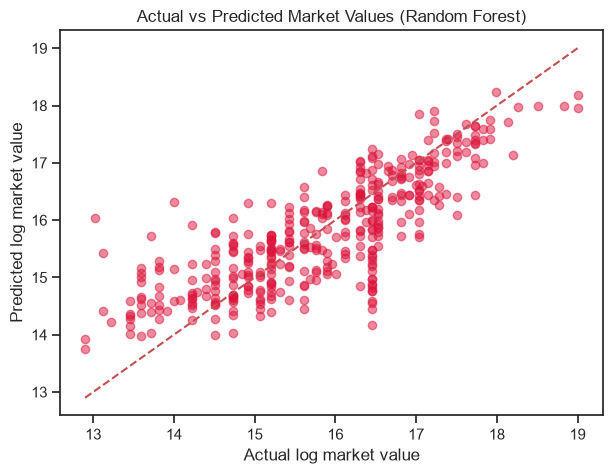

In [163]:
plt.figure(figsize=(7, 5))
plt.scatter(y_val, y_pred_rf, color='crimson' ,alpha=0.5)

plt.xlabel("Actual log market value")
plt.ylabel("Predicted log market value")
plt.title("Actual vs Predicted Market Values (Random Forest)")

lower = min(y_val.min(), y_pred.min())
upper = max(y_val.max(), y_pred.max())

plt.plot([lower, upper], [lower, upper], "r--")
plt.show()

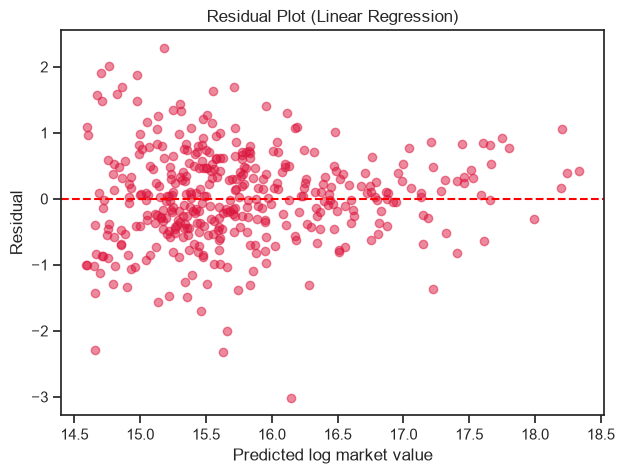

In [165]:
residuals_rf = y_val - y_pred_rf

plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals_rf, color='crimson' ,alpha=0.5)
plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted log market value")
plt.ylabel("Residual")
plt.title("Residual Plot (Linear Regression)")
plt.show()

In [ ]:
from xgboost import XGBRegressor

xgb_regressor = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=2,
    random_state=42,
    n_jobs=-1
)

xgb_regressor.fit(X_train, y_train)

y_pred_xgb = xgb_regressor.predict(X_val)

# print("MAE:", mean_absolute_error(y_val, y_pred_xgb))
# print("RMSE:", np.sqrt(mean_squared_error(y_val, y_pred_xgb)))
# print("R²:", r2_score(y_val, y_pred_xgb))

y_train_pred_xgb = xgb_regressor.predict(X_train)

print("Training R²:", r2_score(y_train, y_train_pred_xgb))
print("Validation R²:", r2_score(y_val, y_pred_xgb))

print("Training MAE:", mean_absolute_error(y_train, y_train_pred_xgb))
print("Validation MAE:", mean_absolute_error(y_val, y_pred_xgb))

Training R²: 0.914677099706837
Validation R²: 0.6360415528283976
Training MAE: 0.26219303160040663
Validation MAE: 0.5484403051461134


In [171]:
from lightgbm import LGBMRegressor

lgbm_regressor = LGBMRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=-1,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgbm_regressor.fit(X_train, y_train)

y_pred_lgbm = lgbm_regressor.predict(X_val)

# print("MAE:", mean_absolute_error(y_val, y_pred_lgbm))
# print("RMSE:", np.sqrt(mean_squared_error(y_val, y_pred_lgbm)))
# print("R²:", r2_score(y_val, y_pred_lgbm))

y_train_pred_lgbm = lgbm_regressor.predict(X_train)

print("Training R²:", r2_score(y_train, y_train_pred_lgbm))
print("Validation R²:", r2_score(y_val, y_pred_lgbm))
print("Training MAE:", mean_absolute_error(y_train, y_train_pred_lgbm))
print("Validation MAE:", mean_absolute_error(y_val, y_pred_lgbm))

Training R²: 0.8866277874575448
Validation R²: 0.6282209435518241
Training MAE: 0.30530432067465846
Validation MAE: 0.5586341113374187


In [173]:
from sklearn.ensemble import GradientBoostingRegressor

gb_regressor = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    min_samples_split=5,
    min_samples_leaf=2,
    loss='squared_error',
    random_state=42
)

gb_regressor.fit(X_train, y_train)

y_pred_gb = gb_regressor.predict(X_val)
y_train_pred_gb = gb_regressor.predict(X_train)

print("Training R²:", r2_score(y_train, y_train_pred_gb))
print("Validation R²:", r2_score(y_val, y_pred_gb))
print("Training MAE:", mean_absolute_error(y_train, y_train_pred_gb))
print("Validation MAE:", mean_absolute_error(y_val, y_pred_gb))
# print("Validation RMSE:", np.sqrt(mean_squared_error(y_val, y_pred_gb)))

Training R²: 0.8085897770815883
Validation R²: 0.6716930152006115
Training MAE: 0.4078461805732131
Validation MAE: 0.5252652139954199


In [175]:
from sklearn.ensemble import ExtraTreesRegressor

et_regressor = ExtraTreesRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

et_regressor.fit(X_train, y_train)

y_pred_et = et_regressor.predict(X_val)
y_train_pred_et = et_regressor.predict(X_train)

print("Training R²:", r2_score(y_train, y_train_pred_et))
print("Validation R²:", r2_score(y_val, y_pred_et))
print("Training MAE:", mean_absolute_error(y_train, y_train_pred_et))
print("Validation MAE:", mean_absolute_error(y_val, y_pred_et))
# print("Validation RMSE:", np.sqrt(mean_squared_error(y_val, y_pred_et)))

Training R²: 0.9544934419167798
Validation R²: 0.6550782766596559
Training MAE: 0.17378216921713377
Validation MAE: 0.5406576038619864


| Model | Training R² | Validation R² | Training MAE | Validation MAE | Validation RMSE |
|---|---:|---:|---:|---:|---:|
| Linear Regression | — | 0.4429 | — | 0.7311 | — |
| Random Forest (Tuned) | 0.8894 | 0.6610 | 0.3005 | 0.5449 | — |
| XGBoost | 0.9147 | 0.6360 | 0.2622 | 0.5484 | 0.7343 |
| LightGBM | 0.8866 | 0.6282 | 0.3053 | 0.5586 | — |
| Gradient Boosting | 0.8086 | 0.6717 | 0.4078 | 0.5253 | — |
| Extra Trees | 0.9545 | 0.6551 | 0.1738 | 0.5407 | — |

Gradient boost has outperformed every model